<div align="center">

# PulsoVision · Classificador de Vazio de Urgência nos Municípios
**Disciplina 06: Machine Learning & Modelling**<br>
Global Solution 2026.2 — FIAP · CitizenTech<br>
Arquivo: `06-machine-learning/modelo_vazio_urgencia.ipynb`

*"A porta de entrada da saúde pra quem não tem médico."*

</div>

**Resumo:** treina e compara modelos que classificam o **risco de um município não ter atendimento de urgência**, isto é, nenhum hospital nem pronto atendimento. A base usa dados reais e oficiais: os 5.571 municípios brasileiros, com a rede de saúde do CNES/DataSUS (set/2026) e a população do IBGE (2026).

É o passo seguinte da trilha de risco do PulsoVision. A disciplina de Estatística mostrou o problema com uma regressão logística de 3 variáveis (acurácia de 84,1%). Aqui o modelo usa toda a rede de saúde do município, compara cinco algoritmos e é ajustado com validação cruzada.

Na seção 9, o modelo entra no app: junto com a triagem por regras e a fila medida pelo totem (disciplinas 01 a 04), ele indica ao cidadão **para onde ir**.

**Integrantes:**
- Tiago Thomaz Cesaro
- Bruno Henrique Ferreira Ambrosio
- Lucas Maximo dos Santos

In [1]:
# No Google Colab, garante as bibliotecas (no computador: pip install -r requirements.txt)
!pip install -q --root-user-action=ignore lightgbm seaborn scikit-learn

In [2]:
import base64
import gzip
import io
import json
import urllib.request
import warnings
from pathlib import Path

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import set_config
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay,
                             accuracy_score, average_precision_score, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, cross_val_predict,
                                     cross_validate, train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=UserWarning)
set_config(transform_output="pandas")   # mantém os nomes das colunas dentro dos Pipelines
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

SEMENTE = 2026
Path("figuras").mkdir(exist_ok=True)

## 1. Problema, público e dados

**Problema.** Em **1.595 municípios** brasileiros, onde vivem **8,8 milhões de pessoas**, não existe nenhum hospital nem pronto atendimento. Quando alguém passa mal de verdade, precisa sair da cidade, muitas vezes sem saber para onde. Já nas cidades grandes o problema é outro: há urgência, mas a porta de entrada (a UBS) é pouca para muita gente, e a fila é longa.

**Público.** Moradores de periferia e interior que dependem do SUS e usam o PulsoVision pelo celular, por voz.

**Pergunta de Machine Learning.** A partir do retrato da rede de saúde e do tamanho de um município, qual o risco de ele **não ter atendimento de urgência**? É uma **classificação binária**: `sem_urgencia` = 1 quando o município não tem hospital nem pronto atendimento ativo no CNES, e 0 quando tem.

**Para que serve no PulsoVision:**
1. dizer ao cidadão de uma cidade sem urgência **para onde ir numa emergência** (seção 9);
2. apontar **onde a falta de urgência é mais inesperada**, para priorizar onde o PulsoVision e o poder público devem chegar primeiro (seção 8);
3. explicar **quais características da rede** estão associadas ao vazio de urgência.

**Fontes, oficiais e públicas:**
- **CNES/DataSUS**, arquivo `tbEstabelecimento202609.csv`, com os estabelecimentos de saúde do Brasil em setembro de 2026;
- **IBGE**, estimativas de população dos municípios em 1º de julho de 2026 (`estimativa_dou_2026.xlsx`).

O script `montar_base_ml.py` junta as duas fontes e gera a `base_municipios_ml.csv`, com uma linha por município. Ele lê só colunas **sem dados pessoais**: nenhum CPF, e-mail ou telefone do CNES sai do arquivo bruto (LGPD).

**ODS:** 3 (Saúde e bem-estar) e 10 (Redução das desigualdades).

### 1.1 Carregar os dados

O notebook roda sozinho, inclusive no Google Colab, sem depender de nenhum outro arquivo:
- se a `base_municipios_ml.csv` estiver na mesma pasta, ele lê o arquivo;
- se não estiver, usa a **mesma base embutida** na célula abaixo, compactada (gzip + base64), com 5.571 linhas e sem dados pessoais. No Colab, essa célula aparece recolhida.

In [3]:
# @title Dados: base_municipios_ml.csv (lida da pasta ou embutida) { display-mode: "form" }
ARQUIVO = Path("base_municipios_ml.csv")
BASE_EMBUTIDA = "..."

if ARQUIVO.exists():
    dados = pd.read_csv(ARQUIVO, dtype={"cod_ibge": str})
    origem = f"do arquivo {ARQUIVO}"
else:
    dados = pd.read_csv(io.BytesIO(gzip.decompress(base64.b64decode(BASE_EMBUTIDA))), dtype={"cod_ibge": str})
    origem = "da base embutida no notebook"
print(f"Dados lidos {origem}: {dados.shape[0]} municípios x {dados.shape[1]} colunas")
dados.head()

Dados lidos da base embutida no notebook: 5571 municípios x 22 colunas


,cod_ibge,municipio,uf,regiao,populacao,estab_sem_urgencia,ubs,consultorios,clinicas,sadt,...,pct_publicos,pct_internet,pct_gestao_estadual,lat,lon,unidades_urgencia,sem_urgencia,km_urgencia,urgencia_mais_proxima,municipio_urgencia
0,1100015,Alta Floresta D'Oeste,RO,Norte,22724,60,11,23,2,6,...,50.0000,78.3300,1.6700,-11.9299,-61.9945,2,0,0.7000,Hospital Parecis,Alta Floresta D'Oeste/RO
1,1100023,Ariquemes,RO,Norte,109731,286,16,144,55,23,...,15.7300,100.0000,2.8000,-9.9156,-63.0350,12,0,0.2000,Hospital Sao Francisco,Ariquemes/RO
2,1100031,Cabixi,RO,Norte,5640,19,3,3,0,2,...,52.6300,94.7400,0.0000,-13.4942,-60.5421,1,0,0.6000,Hospital Municipal De Cabixi Hpp,Cabixi/RO
3,1100049,Cacoal,RO,Norte,98884,603,14,420,52,23,...,8.4600,98.1800,2.6500,-11.4362,-61.4493,12,0,0.1000,Hospital E Maternidade Sao Paulo,Cacoal/RO
4,1100056,Cerejeiras,RO,Norte,16957,42,4,10,13,6,...,35.7100,97.6200,7.1400,-13.1896,-60.8180,1,0,0.7000,Hospital Municipal Sao Lucas,Cerejeiras/RO


**Dicionário das variáveis:**

| Grupo | Variáveis | Uso |
|---|---|---|
| Identificação | `cod_ibge`, `municipio`, `uf` | Só para mostrar resultados |
| Território | `regiao`, `populacao` | Atributos (`populacao` entra em log10) |
| Rede de saúde **sem** urgência | `estab_sem_urgencia`, `ubs`, `consultorios`, `clinicas`, `sadt` (apoio diagnóstico), `farmacias`, `caps` (saúde mental) | Atributos, transformados em taxa por 10 mil habitantes |
| Perfil da rede | `pct_publicos`, `pct_internet`, `pct_gestao_estadual` (% sob gestão do estado) | Atributos |
| Alvo | `sem_urgencia` (1 = nenhum hospital nem pronto atendimento) | O que o modelo prevê |
| Contagem do alvo | `unidades_urgencia` | **Fora**: é o próprio alvo em número (vazamento) |
| Aplicação | `lat`, `lon`, `km_urgencia`, `urgencia_mais_proxima`, `municipio_urgencia` | **Fora** do modelo: servem só para orientar o cidadão na seção 9 |

Os hospitais e prontos atendimentos foram **retirados de todas as contagens** usadas como atributo, porque são eles que definem o alvo.

## 2. Análise exploratória (EDA)

### 2.1 Qualidade dos dados

In [4]:
qualidade = pd.DataFrame({
    "tipo": dados.dtypes.astype(str),
    "ausentes": dados.isna().sum(),
    "valores distintos": dados.nunique(),
})
print(f"Municípios duplicados (cod_ibge): {dados['cod_ibge'].duplicated().sum()}")
print(f"Municípios sem nenhum estabelecimento no CNES: {(dados['estab_sem_urgencia'] == 0).sum()}")
qualidade

Municípios duplicados (cod_ibge): 0
Municípios sem nenhum estabelecimento no CNES: 0


,tipo,ausentes,valores distintos
cod_ibge,str,0,5571
municipio,str,0,5298
uf,str,0,27
regiao,str,0,5
populacao,int64,0,5088
estab_sem_urgencia,int64,0,512
ubs,int64,0,95
consultorios,int64,0,378
clinicas,int64,0,211
sadt,int64,0,115


In [5]:
dados[["populacao", "estab_sem_urgencia", "ubs", "consultorios", "clinicas", "sadt",
       "farmacias", "caps", "pct_publicos", "pct_internet", "pct_gestao_estadual"]].describe().T

,count,mean,std,min,25%,50%,75%,max
populacao,"5,571.0000","38,451.2567","217,690.0014",857.0000,"5,342.0000","11,386.0000","25,399.5000","11,911,337.0000"
estab_sem_urgencia,"5,571.0000",88.4048,553.0128,2.0000,10.0000,19.0000,44.0000,"29,428.0000"
ubs,"5,571.0000",9.1066,14.3036,0.0000,3.0000,6.0000,11.0000,546.0000
consultorios,"5,571.0000",41.1520,322.2433,0.0000,0.0000,2.0000,11.0000,"17,951.0000"
clinicas,"5,571.0000",16.9743,158.0882,0.0000,0.0000,2.0000,6.0000,"7,623.0000"
sadt,"5,571.0000",5.7589,23.0675,0.0000,0.0000,1.0000,4.0000,936.0000
farmacias,"5,571.0000",5.5566,22.8023,0.0000,0.0000,1.0000,4.0000,991.0000
caps,"5,571.0000",0.6589,1.9150,0.0000,0.0000,0.0000,1.0000,107.0000
pct_publicos,"5,571.0000",59.7884,29.6454,3.2700,33.3300,61.5400,86.6700,100.0000
pct_internet,"5,571.0000",86.8923,16.1648,9.0900,80.0000,92.5700,100.0000,100.0000


**Leitura da qualidade:**
- A base não tem valores ausentes nem municípios duplicados, e todos os 5.571 municípios do IBGE foram encontrados no CNES. Mesmo assim, o pré-processamento inclui um `SimpleImputer`, para o modelo funcionar se um dado faltar no futuro.
- As contagens são **muito assimétricas**: a população vai de 857 a 11,9 milhões de habitantes. Por isso, a população entra em **log10**, e as contagens viram **taxas por 10 mil habitantes**. Contagens brutas só repetiriam o tamanho da cidade.
- Municípios muito pequenos podem ter taxas altas só por terem poucos habitantes; por exemplo, 2 UBS para 1.000 pessoas dão 20 UBS por 10 mil. Esses valores são reais, não erros, então ficam na base. A padronização e os modelos de árvore lidam bem com eles.

### 2.2 Variável alvo

sem_urgencia
Tem urgência    3976
Sem urgência    1595

28.6% dos municípios não têm hospital nem pronto atendimento
Moram neles 8.8 milhões de pessoas (4.1% da população)


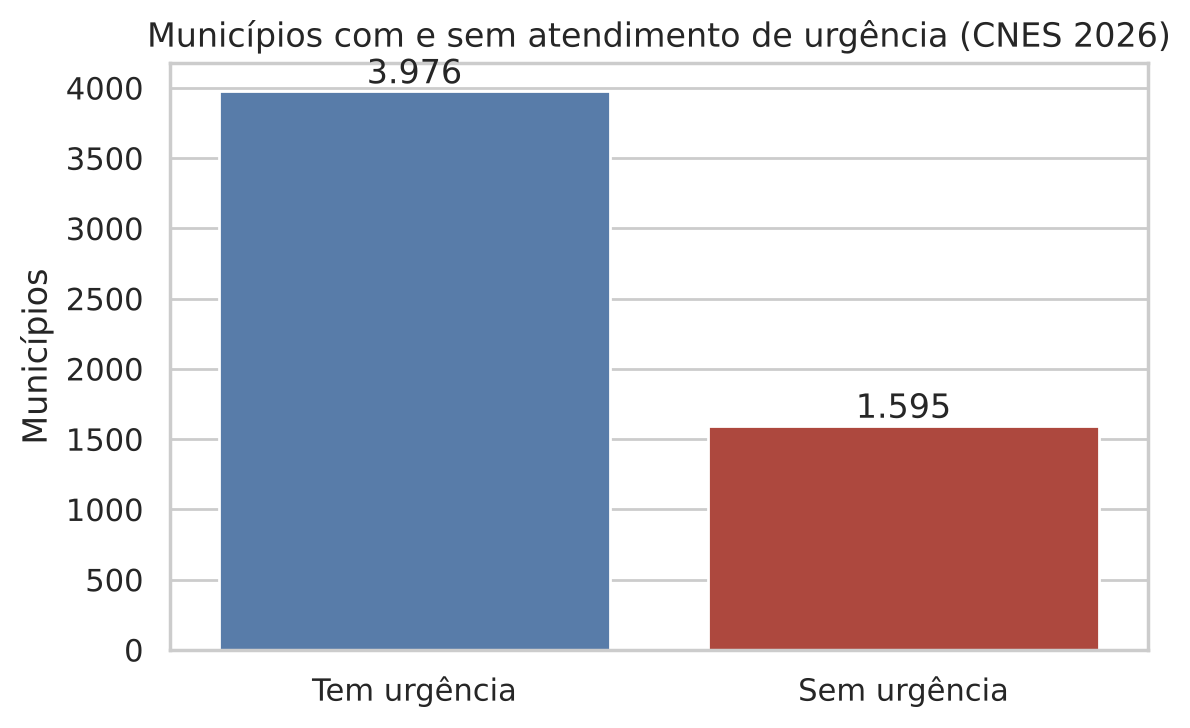

In [6]:
contagem = dados["sem_urgencia"].value_counts().rename({0: "Tem urgência", 1: "Sem urgência"})
pessoas = dados.groupby("sem_urgencia")["populacao"].sum().rename({0: "Tem urgência", 1: "Sem urgência"})
print(contagem.to_string())
print(f"\n{100 * dados['sem_urgencia'].mean():.1f}% dos municípios não têm hospital nem pronto atendimento")
print(f"Moram neles {pessoas['Sem urgência'] / 1e6:.1f} milhões de pessoas "
      f"({100 * pessoas['Sem urgência'] / pessoas.sum():.1f}% da população)")

fig, ax = plt.subplots(figsize=(6, 3.8))
sns.barplot(x=contagem.index, y=contagem.values, hue=contagem.index, palette=["#4a7bb7", "#c0392b"], legend=False, ax=ax)
for i, v in enumerate(contagem.values):
    ax.text(i, v, f"{v:,}".replace(",", "."), ha="center", va="bottom")
ax.set_title("Municípios com e sem atendimento de urgência (CNES 2026)")
ax.set_ylabel("Municípios")
ax.set_xlabel("")
plt.tight_layout()
plt.savefig("figuras/01_alvo.png", dpi=150)
plt.show()

As classes são **desbalanceadas**: 71% dos municípios têm urgência e 29% não têm. Um modelo que respondesse sempre "tem urgência" acertaria 71% sem aprender nada. Por isso, a acurácia não é a métrica principal. As métricas escolhidas são:
- **ROC-AUC**, que mede se o modelo ordena bem os municípios por risco;
- **PR-AUC** (average precision), que mede o desempenho na classe de interesse;
- **recall** dos municípios sem urgência, porque deixar um deles de fora é o erro mais caro.

### 2.3 Onde está o vazio de urgência?

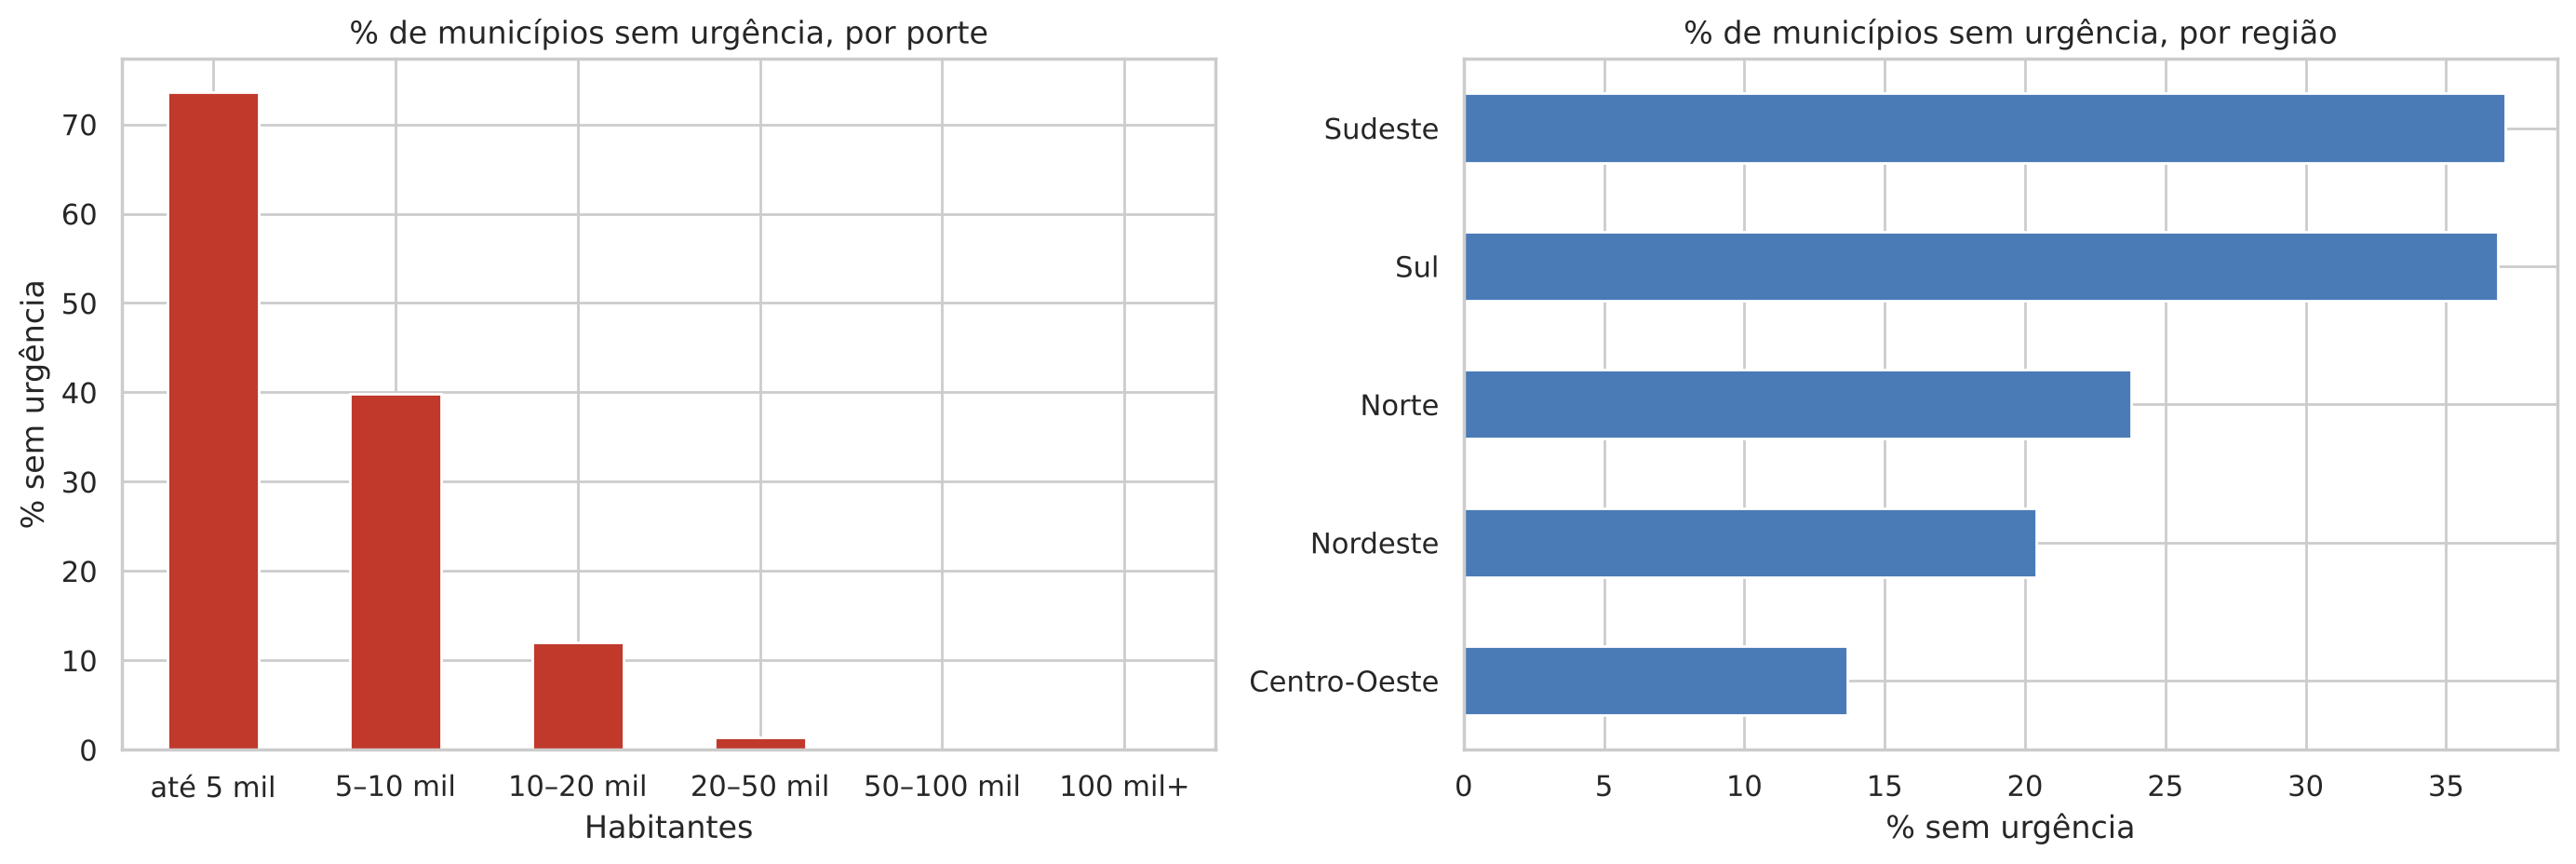

,municípios,taxa sem urgência
populacao,,
até 5 mil,1286,0.7364
5–10 mil,1181,0.3988
10–20 mil,1349,0.1201
20–50 mil,1068,0.0140
50–100 mil,349,0.0000
100 mil+,338,0.0000


In [7]:
faixas = pd.cut(dados["populacao"], [0, 5_000, 10_000, 20_000, 50_000, 100_000, np.inf],
                labels=["até 5 mil", "5–10 mil", "10–20 mil", "20–50 mil", "50–100 mil", "100 mil+"])
por_porte = dados.groupby(faixas, observed=True)["sem_urgencia"].agg(["size", "mean"])
por_regiao = dados.groupby("regiao")["sem_urgencia"].mean().sort_values()

fig, eixos = plt.subplots(1, 2, figsize=(14, 4.8))
(100 * por_porte["mean"]).plot.bar(ax=eixos[0], color="#c0392b")
eixos[0].set_title("% de municípios sem urgência, por porte")
eixos[0].set_xlabel("Habitantes")
eixos[0].set_ylabel("% sem urgência")
eixos[0].tick_params(axis="x", rotation=0)
(100 * por_regiao).plot.barh(ax=eixos[1], color="#4a7bb7")
eixos[1].set_title("% de municípios sem urgência, por região")
eixos[1].set_xlabel("% sem urgência")
eixos[1].set_ylabel("")
plt.tight_layout()
plt.savefig("figuras/02_onde.png", dpi=150)
plt.show()
por_porte.rename(columns={"size": "municípios", "mean": "taxa sem urgência"})

**Leitura:**
- O vazio de urgência é um problema de **cidade pequena**: atinge cerca de 3 em cada 4 municípios com até 5 mil habitantes e praticamente desaparece acima de 50 mil.
- Há diferença entre as **regiões**, então a região entra como atributo categórico.
- O tamanho da cidade explica muito, mas não tudo: dois municípios do mesmo porte podem ter redes bem diferentes. É isso que o modelo vai explorar.

### 2.4 Engenharia de atributos e comparação entre as classes

As contagens viram **taxas por 10 mil habitantes**, e a população entra em **log10**. São regras fixas, que não aprendem nada dos dados, por isso podem ser aplicadas antes da divisão entre treino e teste sem causar vazamento.

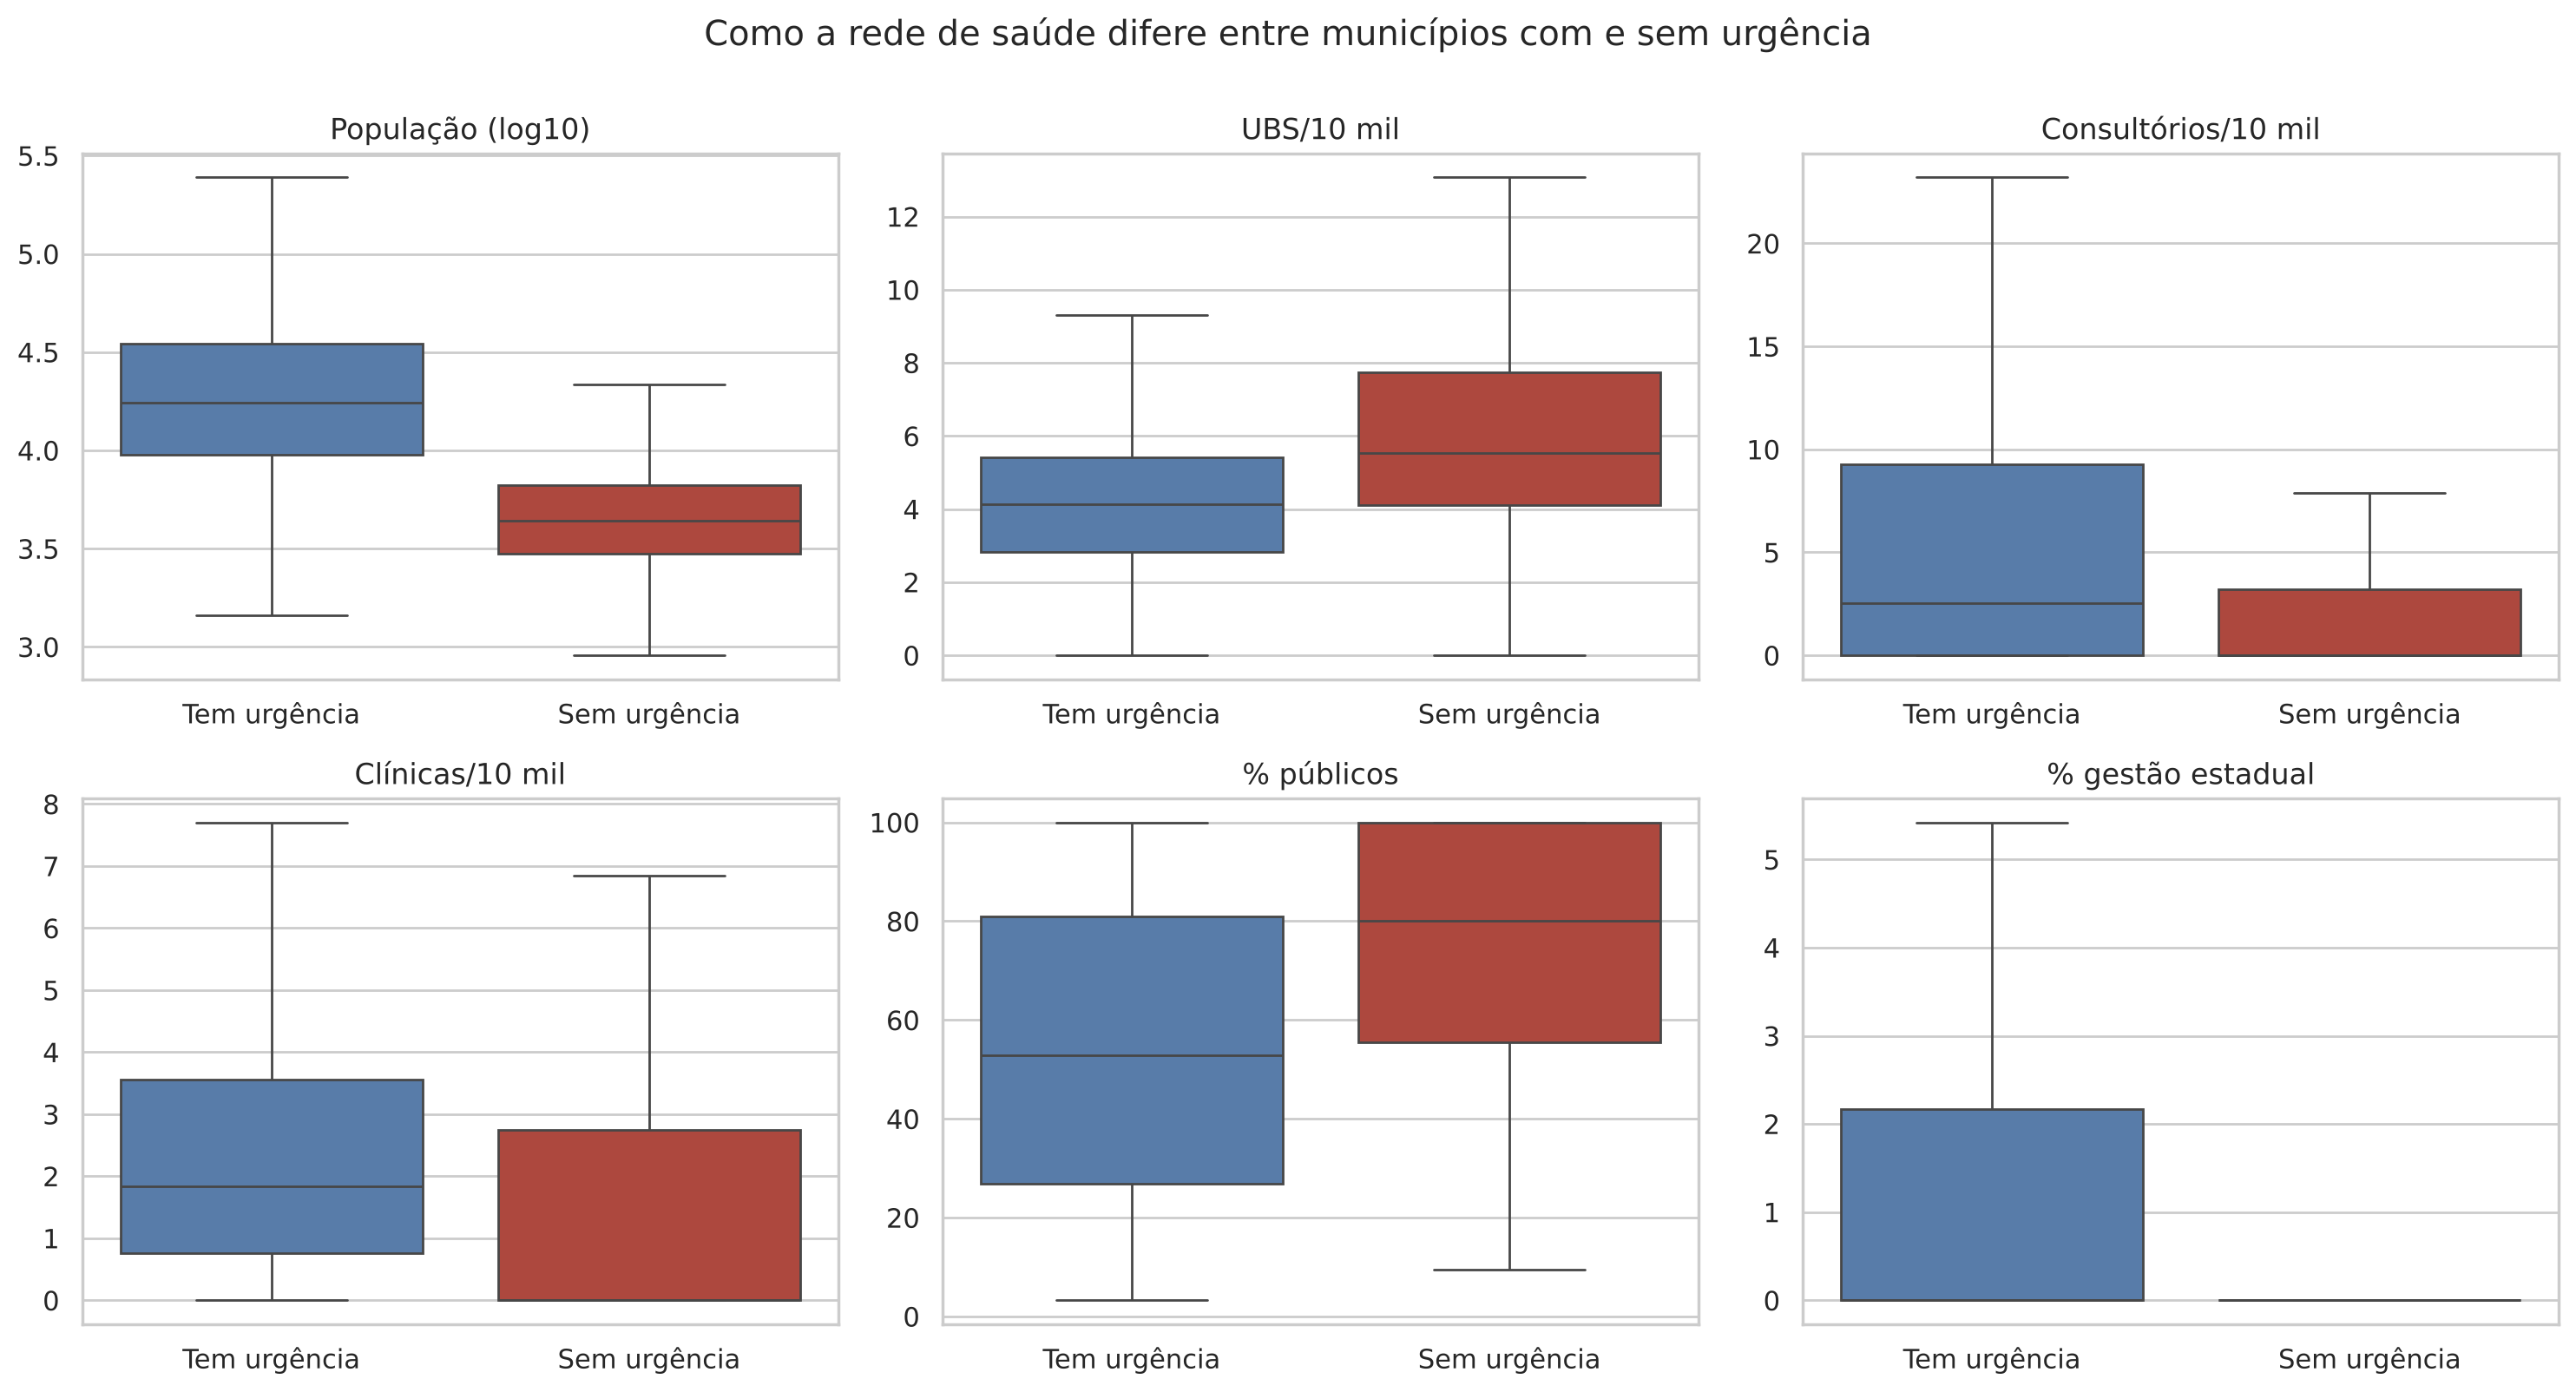

sem_urgencia,mediana: tem urgência,mediana: sem urgência
log10_populacao,4.2438,3.6418
estab_sem_urgencia_10mil,17.6658,18.9681
ubs_10mil,4.1258,5.5417
consultorios_10mil,2.5302,0.0000
clinicas_10mil,1.8363,0.0000
sadt_10mil,1.3844,1.2977
farmacias_10mil,1.0261,1.4162
caps_10mil,0.1537,0.0000
pct_publicos,52.9400,80.0000
pct_internet,91.9800,100.0000


In [8]:
CONTAGENS = ["estab_sem_urgencia", "ubs", "consultorios", "clinicas", "sadt", "farmacias", "caps"]
NUMERICAS = (["log10_populacao"] + [f"{c}_10mil" for c in CONTAGENS]
             + ["pct_publicos", "pct_internet", "pct_gestao_estadual"])
CATEGORICAS = ["regiao"]
ATRIBUTOS = NUMERICAS + CATEGORICAS
NOMES = {"log10_populacao": "População (log10)", "estab_sem_urgencia_10mil": "Estabelecimentos/10 mil",
         "ubs_10mil": "UBS/10 mil", "consultorios_10mil": "Consultórios/10 mil", "clinicas_10mil": "Clínicas/10 mil",
         "sadt_10mil": "Apoio diagnóstico/10 mil", "farmacias_10mil": "Farmácias/10 mil", "caps_10mil": "CAPS/10 mil",
         "pct_publicos": "% públicos", "pct_internet": "% com internet", "pct_gestao_estadual": "% gestão estadual"}


def criar_atributos(df: pd.DataFrame) -> pd.DataFrame:
    novo = df.copy()
    novo["log10_populacao"] = np.log10(novo["populacao"])
    for coluna in CONTAGENS:
        novo[f"{coluna}_10mil"] = novo[coluna] / novo["populacao"] * 10_000
    return novo


base = criar_atributos(dados)
mostrar = ["log10_populacao", "ubs_10mil", "consultorios_10mil", "clinicas_10mil", "pct_publicos", "pct_gestao_estadual"]
fig, eixos = plt.subplots(2, 3, figsize=(15, 8))
for eixo, coluna in zip(eixos.ravel(), mostrar):
    sns.boxplot(data=base, x="sem_urgencia", y=coluna, hue="sem_urgencia", palette=["#4a7bb7", "#c0392b"],
                legend=False, showfliers=False, ax=eixo)
    eixo.set_title(NOMES[coluna])
    eixo.set_xlabel("")
    eixo.set_ylabel("")
    eixo.set_xticks([0, 1], ["Tem urgência", "Sem urgência"])
plt.suptitle("Como a rede de saúde difere entre municípios com e sem urgência", y=1.0)
plt.tight_layout()
plt.savefig("figuras/03_classes.png", dpi=150)
plt.show()
base.groupby("sem_urgencia")[NUMERICAS].median().T.rename(columns={0: "mediana: tem urgência", 1: "mediana: sem urgência"})

**Leitura:**
- Os municípios **sem urgência** são menores e têm **mais UBS por habitante**: a atenção básica existe, mas está sozinha.
- Eles têm **menos consultórios e clínicas** por habitante, ou seja, quase não há rede privada nem especializada.
- A rede deles é **mais pública**: o SUS é praticamente o único que está lá.

Esse retrato é o mesmo que a disciplina de Estatística encontrou e reforça a ideia do PulsoVision: nesses lugares, o cidadão tem a UBS por perto, mas precisa ser **orientado para fora da cidade** quando o caso é grave.

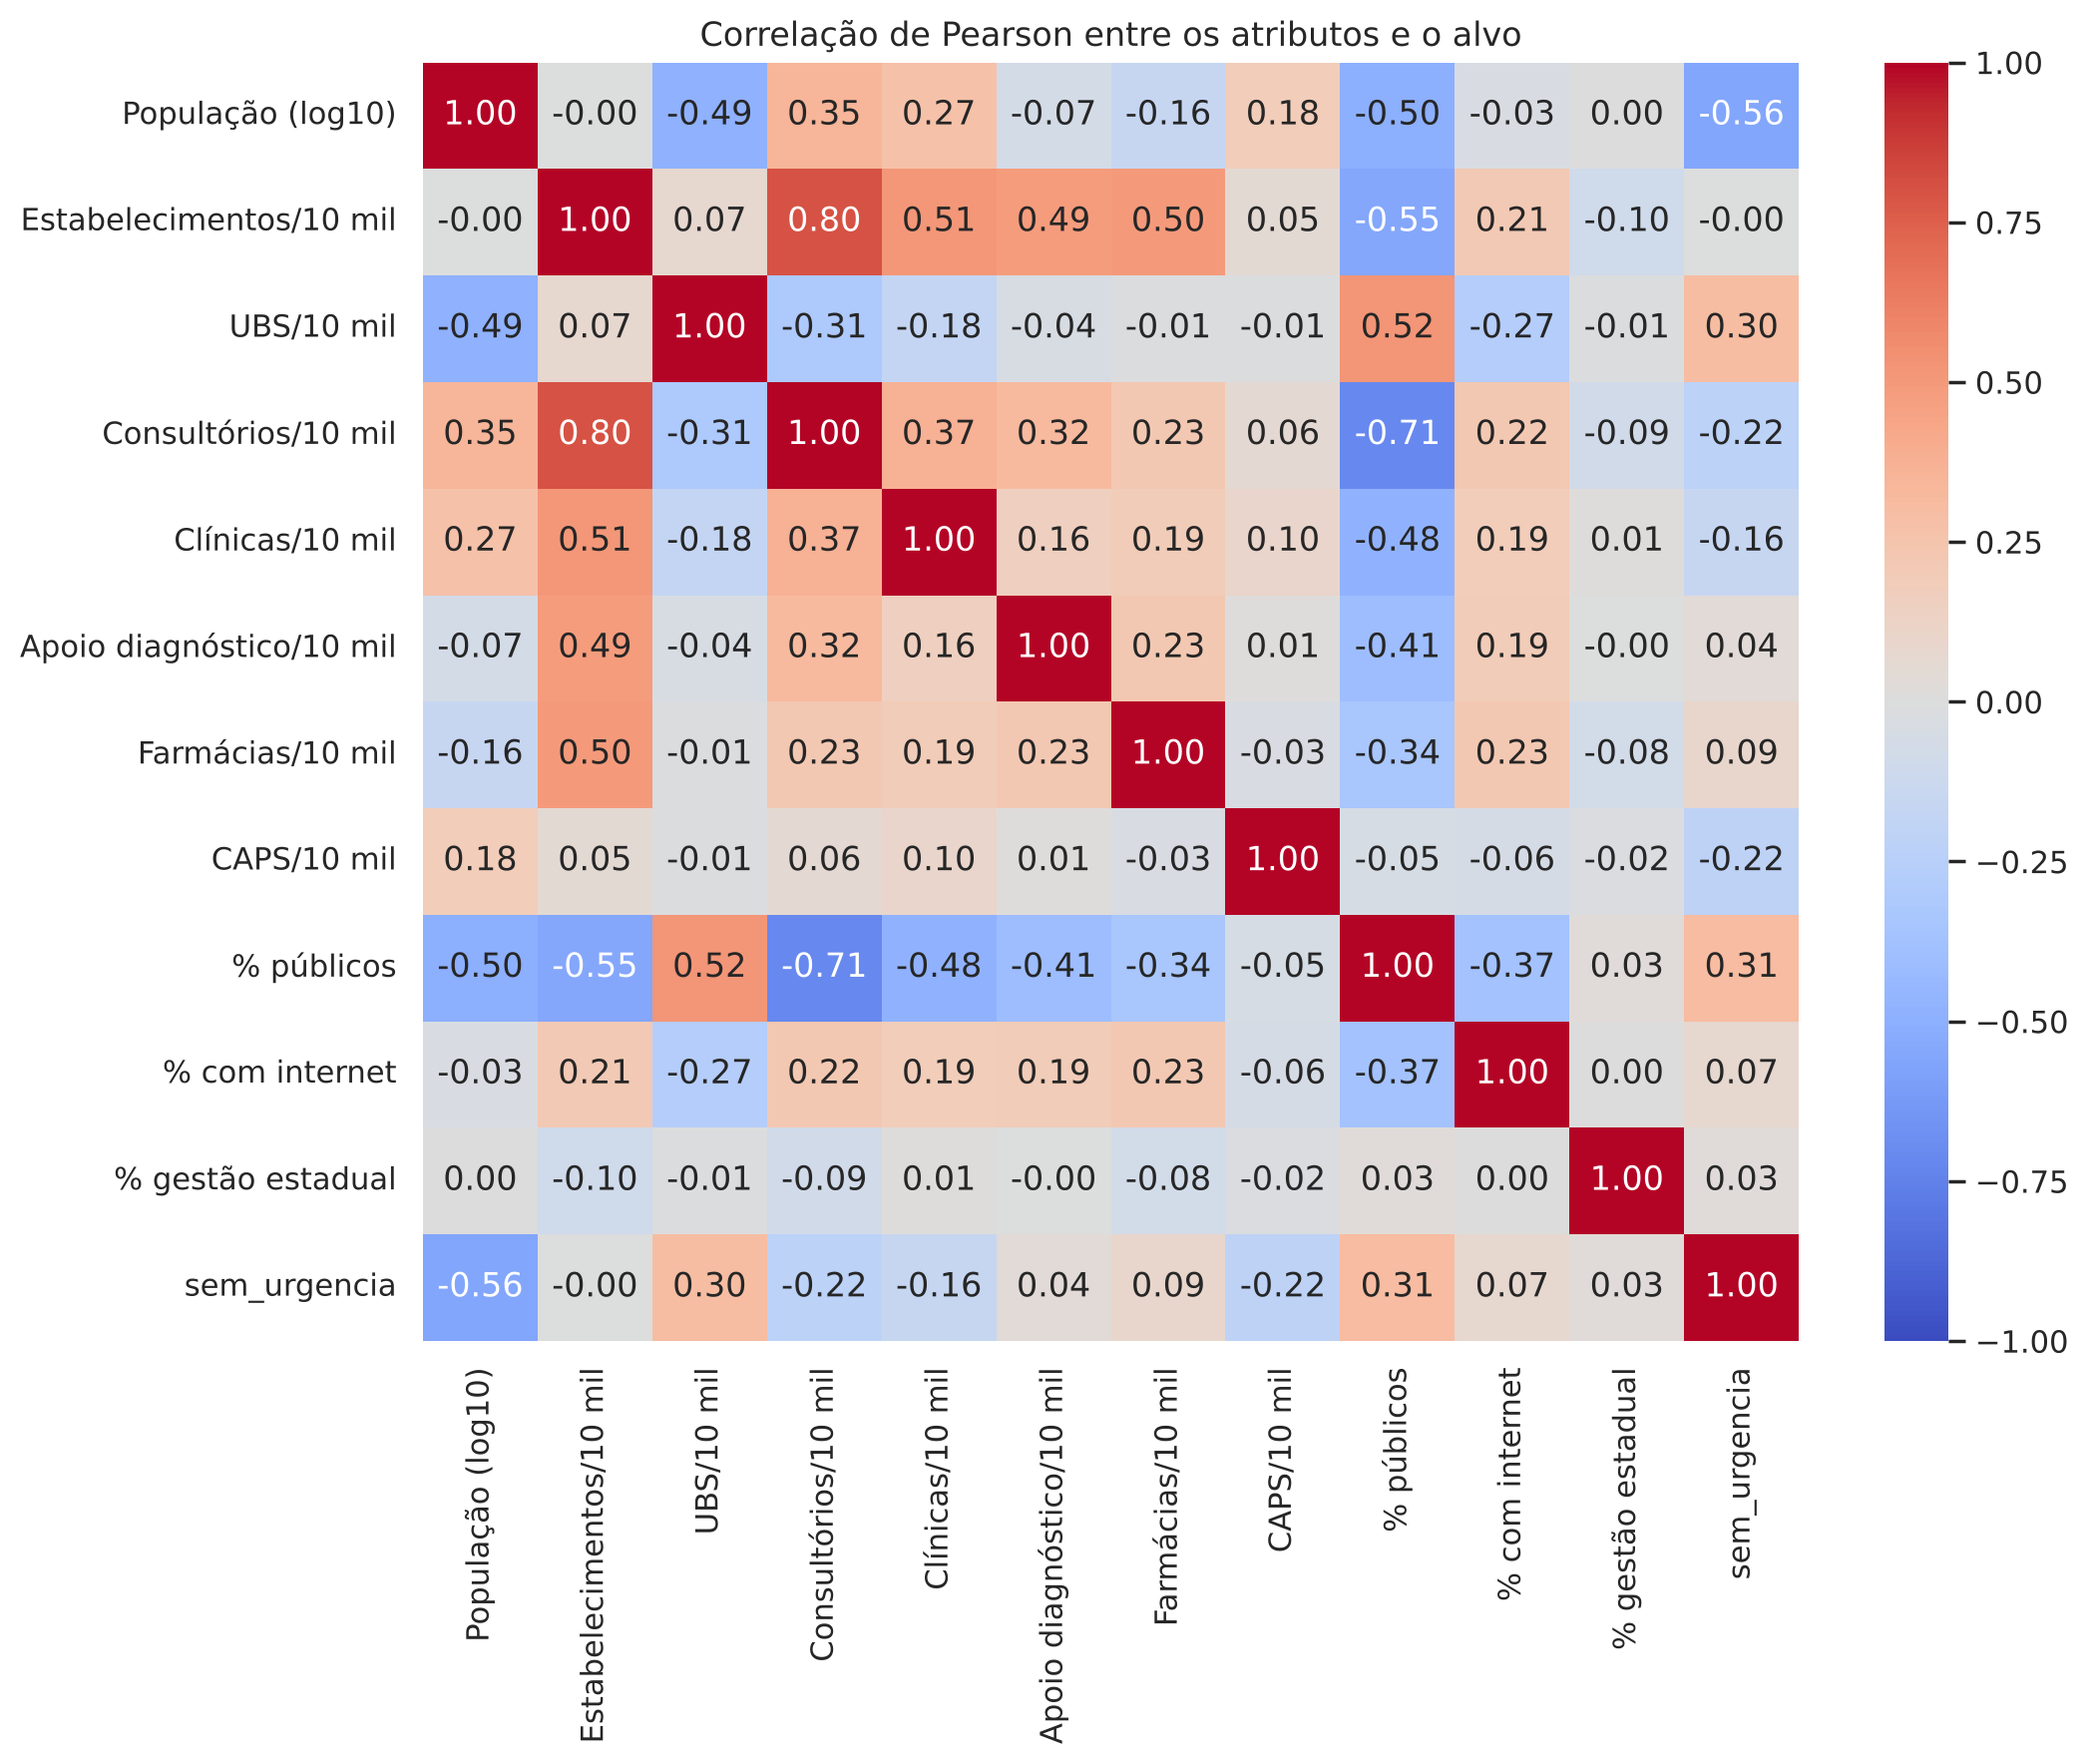

In [9]:
plt.figure(figsize=(11, 9))
sns.heatmap(base[NUMERICAS + ["sem_urgencia"]].rename(columns=NOMES).corr(), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlação de Pearson entre os atributos e o alvo")
plt.tight_layout()
plt.savefig("figuras/04_correlacao.png", dpi=150)
plt.show()

- A **população (log10)** é o atributo mais ligado ao alvo, com correlação negativa: quanto maior a cidade, menor o risco.
- As taxas de consultórios e clínicas também se ligam ao alvo, de forma negativa.
- **Estabelecimentos/10 mil** se correlaciona com as taxas que o compõem, o que é esperado, porque é o total. Isso não atrapalha os modelos de árvore. Na regressão logística, a regularização L2 (padrão do scikit-learn) controla os coeficientes.

### 2.5 Cuidado com vazamento de dados (data leakage)

Ficam **fora** do modelo:
- `unidades_urgencia`, que é o próprio alvo em forma de contagem;
- `km_urgencia`, que vale quase zero em quem tem urgência e, por isso, entregaria a resposta;
- `lat` e `lon`, que deixariam o modelo decorar o mapa em vez de aprender o perfil da rede.

Os hospitais e prontos atendimentos também foram retirados de todas as contagens e percentuais.

## 3. Pré-processamento

### 3.1 Divisão treino/teste

In [10]:
X = base[ATRIBUTOS]
y = base["sem_urgencia"]
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEMENTE)
print(f"Treino: {len(X_treino)} municípios, {100 * y_treino.mean():.1f}% sem urgência")
print(f"Teste:  {len(X_teste)} municípios, {100 * y_teste.mean():.1f}% sem urgência")
validacao = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)

Treino: 4456 municípios, 28.6% sem urgência
Teste:  1115 municípios, 28.6% sem urgência


A divisão é **estratificada**, para manter a mesma proporção de municípios sem urgência nos dois conjuntos. Os 20% de teste ficam guardados até a avaliação final.

### 3.2 Pipeline: padronização e codificação sem vazamento

Todo o pré-processamento fica num `ColumnTransformer` **dentro de um `Pipeline`**:
- nas numéricas, `SimpleImputer(median)` seguido de `StandardScaler` (média 0, desvio 1);
- na região, `OneHotEncoder`, que cria uma coluna 0/1 para cada região.

A média, o desvio e as categorias são aprendidos **apenas no treino de cada dobra** da validação cruzada, nunca no teste. Isso evita o vazamento.

**A padronização importa?** Depende do algoritmo. O KNN mede distâncias, então uma variável em escala grande, como `% públicos` (0 a 100), dominaria outra em escala pequena, como `População (log10)`, que vai de 3 a 7. O teste abaixo mostra o efeito.

In [11]:
def preparo(padronizar: bool) -> ColumnTransformer:
    numericas = Pipeline([("imputar", SimpleImputer(strategy="median"))]
                         + ([("padronizar", StandardScaler())] if padronizar else []))
    return ColumnTransformer([
        ("num", numericas, NUMERICAS),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAS),
    ], verbose_feature_names_out=False)


efeito_escala = {}
for padronizar in (False, True):
    knn = Pipeline([("preparo", preparo(padronizar)), ("modelo", KNeighborsClassifier(n_neighbors=15))])
    auc = cross_validate(knn, X_treino, y_treino, cv=validacao, scoring="roc_auc")["test_score"].mean()
    efeito_escala["KNN com StandardScaler" if padronizar else "KNN sem padronizar"] = auc
pd.Series(efeito_escala, name="ROC-AUC na validação").to_frame()

,ROC-AUC na validação
KNN sem padronizar,0.7996
KNN com StandardScaler,0.8861


Sem padronizar, o KNN perde muito desempenho, porque as distâncias passam a ser decididas pelas variáveis de escala maior. Com o `StandardScaler`, todas pesam igual. Por isso, a padronização entra no Pipeline da **Regressão Logística** e do **KNN**. Árvore, Random Forest e LightGBM não precisam dela, porque dividem os dados por limiares, e a escala não muda a ordem dos valores. O desbalanceamento é tratado com `class_weight="balanced"`: o erro na classe menor pesa mais no treino, e nenhum dado é inventado.

## 4. Modelagem: baseline e comparação

| Modelo | Por que entra |
|---|---|
| **Baseline** (`DummyClassifier`) | Chuta respeitando a proporção das classes. É a régua que todo modelo precisa superar |
| **Regressão Logística** | Simples, estável e interpretável (razão de chances). A mesma família usada na Estatística, agora com todos os atributos |
| **KNN** | Classifica pelos municípios mais parecidos: "cidades como a sua costumam ter urgência?" |
| **Árvore de Decisão** | Gera regras legíveis e captura relações não lineares |
| **Random Forest** | Combina muitas árvores e reduz a variância de uma árvore só |
| **LightGBM** | Boosting de gradiente, forte em dados tabulares |

Todos são comparados com **validação cruzada estratificada de 5 dobras**, só no treino.

In [12]:
modelos = {
    "Baseline (Dummy)": Pipeline([("preparo", preparo(False)),
                                  ("modelo", DummyClassifier(strategy="stratified", random_state=SEMENTE))]),
    "Regressão Logística": Pipeline([("preparo", preparo(True)),
                                     ("modelo", LogisticRegression(max_iter=3000, class_weight="balanced"))]),
    "KNN": Pipeline([("preparo", preparo(True)), ("modelo", KNeighborsClassifier(n_neighbors=15))]),
    "Árvore de Decisão": Pipeline([("preparo", preparo(False)), ("modelo", DecisionTreeClassifier(
        max_depth=6, class_weight="balanced", random_state=SEMENTE))]),
    "Random Forest": Pipeline([("preparo", preparo(False)), ("modelo", RandomForestClassifier(
        n_estimators=400, min_samples_leaf=3, class_weight="balanced", n_jobs=-1, random_state=SEMENTE))]),
    "LightGBM": Pipeline([("preparo", preparo(False)), ("modelo", lgb.LGBMClassifier(
        n_estimators=300, learning_rate=0.05, class_weight="balanced", random_state=SEMENTE, verbose=-1))]),
}
metricas = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "recall": "recall", "f1": "f1", "acuracia": "accuracy"}
linhas = []
for nome, modelo in modelos.items():
    r = cross_validate(modelo, X_treino, y_treino, cv=validacao, scoring=metricas, return_train_score=True)
    linhas.append({"modelo": nome,
                   "ROC-AUC treino": r["train_roc_auc"].mean(), "ROC-AUC validação": r["test_roc_auc"].mean(),
                   "± desvio": r["test_roc_auc"].std(), "PR-AUC validação": r["test_pr_auc"].mean(),
                   "Recall validação": r["test_recall"].mean(), "F1 validação": r["test_f1"].mean(),
                   "Acurácia validação": r["test_acuracia"].mean()})
comparacao = pd.DataFrame(linhas).set_index("modelo")
comparacao["gap treino-validação"] = comparacao["ROC-AUC treino"] - comparacao["ROC-AUC validação"]
comparacao.sort_values("ROC-AUC validação", ascending=False)

,ROC-AUC treino,ROC-AUC validação,± desvio,PR-AUC validação,Recall validação,F1 validação,Acurácia validação,gap treino-validação
modelo,,,,,,,,
Regressão Logística,0.9163,0.9138,0.0071,0.8056,0.8456,0.7311,0.8218,0.0024
Random Forest,0.9944,0.9126,0.0085,0.7938,0.8182,0.7371,0.8326,0.0818
LightGBM,0.9995,0.9030,0.0058,0.7809,0.7586,0.7216,0.8324,0.0966
KNN,0.9176,0.8861,0.0118,0.7286,0.6066,0.6596,0.8207,0.0316
Árvore de Decisão,0.9352,0.8802,0.0047,0.7306,0.8542,0.7074,0.7971,0.0550
Baseline (Dummy),0.5010,0.5130,0.0211,0.2929,0.3001,0.3026,0.6039,-0.0119


**Leitura da comparação:**
- O **baseline** fica em ROC-AUC ≈ 0,51, que é chute. Todos os modelos o superam com folga.
- A **Regressão Logística** chega a uma ROC-AUC de **0,914 praticamente sem gap** entre treino e validação (0,002): aprende um padrão estável.
- **Random Forest** (0,913) e **LightGBM** (0,903) chegam perto na validação, mas com ROC-AUC de treino de 0,99 a 1,00. Isso é **overfitting**: eles decoram os municípios do treino.
- A **Árvore** (0,880) e o **KNN** (0,886) ficam abaixo.

A próxima etapa ajusta os hiperparâmetros para tentar reduzir o overfitting.

## 5. Otimização de hiperparâmetros (GridSearchCV)

São feitas duas buscas, com a mesma validação estratificada de 5 dobras e otimizando a **ROC-AUC**:
1. **LightGBM**, o modelo com o maior overfitting. A grade controla a complexidade: `num_leaves` (folhas por árvore), `min_child_samples` (mínimo de municípios por folha), `learning_rate` e `n_estimators` (passo e número de árvores) e `reg_lambda` (penalização L2).
2. **Regressão Logística**, para escolher a força da regularização `C`: quanto menor o `C`, mais os coeficientes são encolhidos.

In [13]:
# n_jobs=1 no LightGBM e paralelismo no GridSearchCV: evita disputar os núcleos do processador
grade_lgbm = {
    "modelo__num_leaves": [7, 15, 31],
    "modelo__min_child_samples": [20, 50],
    "modelo__learning_rate": [0.03, 0.1],
    "modelo__n_estimators": [200, 400],
    "modelo__reg_lambda": [0.0, 5.0],
}
busca_lgbm = GridSearchCV(modelos["LightGBM"].set_params(modelo__n_jobs=1), grade_lgbm, cv=validacao,
                          scoring="roc_auc", return_train_score=True, n_jobs=-1).fit(X_treino, y_treino)

grade_lr = {"modelo__C": [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0]}
busca_lr = GridSearchCV(modelos["Regressão Logística"], grade_lr, cv=validacao,
                        scoring="roc_auc", return_train_score=True, n_jobs=-1).fit(X_treino, y_treino)


def resumo_busca(busca):
    r = pd.DataFrame(busca.cv_results_)
    melhor = r.loc[r["rank_test_score"] == 1].iloc[0]
    return melhor["mean_train_score"], melhor["mean_test_score"]


print(f"LightGBM: {len(busca_lgbm.cv_results_['params'])} combinações x 5 dobras = "
      f"{5 * len(busca_lgbm.cv_results_['params'])} treinos")
print("  melhores:", {k.replace("modelo__", ""): v for k, v in busca_lgbm.best_params_.items()})
print(f"Regressão Logística: melhor C = {busca_lr.best_params_['modelo__C']}")

antes_depois = pd.DataFrame({
    "LightGBM padrão": [comparacao.loc["LightGBM", "ROC-AUC treino"], comparacao.loc["LightGBM", "ROC-AUC validação"]],
    "LightGBM ajustado": resumo_busca(busca_lgbm),
    "Reg. Logística padrão": [comparacao.loc["Regressão Logística", "ROC-AUC treino"],
                              comparacao.loc["Regressão Logística", "ROC-AUC validação"]],
    "Reg. Logística ajustada": resumo_busca(busca_lr),
}, index=["ROC-AUC treino", "ROC-AUC validação"]).T
antes_depois["gap"] = antes_depois["ROC-AUC treino"] - antes_depois["ROC-AUC validação"]
antes_depois

LightGBM: 48 combinações x 5 dobras = 240 treinos
  melhores: {'learning_rate': 0.03, 'min_child_samples': 50, 'n_estimators': 400, 'num_leaves': 7, 'reg_lambda': 5.0}
Regressão Logística: melhor C = 1.0


,ROC-AUC treino,ROC-AUC validação,gap
LightGBM padrão,0.9995,0.9030,0.0966
LightGBM ajustado,0.9446,0.9134,0.0312
Reg. Logística padrão,0.9163,0.9138,0.0024
Reg. Logística ajustada,0.9163,0.9138,0.0024


**Leitura do tuning:** - **LightGBM:** a busca escolheu árvores bem menores, com 7 folhas, mínimo de 50 municípios por folha, passo 0,03 e L2 = 5. A ROC-AUC de validação **subiu de 0,903 para 0,913**, e o gap entre treino e validação **caiu de 0,097 para 0,031**. O overfitting foi controlado.
- **Regressão Logística:** o melhor `C` foi 1,0, que já é o padrão. O modelo não tinha overfitting (gap de 0,002), e regularizar mais não ajudou.

## 6. Avaliação final no conjunto de teste

Os finalistas são treinados no treino completo e avaliados **uma única vez** nos 20% de teste, que nenhum modelo viu.

In [14]:
finalistas = {
    "Baseline (Dummy)": modelos["Baseline (Dummy)"].fit(X_treino, y_treino),
    "Regressão Logística ajustada": busca_lr.best_estimator_,
    "Random Forest": modelos["Random Forest"].fit(X_treino, y_treino),
    "LightGBM ajustado": busca_lgbm.best_estimator_,
}
probabilidades, linhas = {}, []
for nome, modelo in finalistas.items():
    p_teste = modelo.predict_proba(X_teste)[:, 1]
    probabilidades[nome] = p_teste
    previsto = (p_teste >= 0.5).astype(int)
    linhas.append({"modelo": nome,
                   "ROC-AUC treino": roc_auc_score(y_treino, modelo.predict_proba(X_treino)[:, 1]),
                   "ROC-AUC teste": roc_auc_score(y_teste, p_teste),
                   "PR-AUC teste": average_precision_score(y_teste, p_teste),
                   "Acurácia (0,5)": accuracy_score(y_teste, previsto),
                   "Precisão (0,5)": precision_score(y_teste, previsto, zero_division=0),
                   "Recall (0,5)": recall_score(y_teste, previsto),
                   "F1 (0,5)": f1_score(y_teste, previsto)})
avaliacao = pd.DataFrame(linhas).set_index("modelo")
avaliacao

,ROC-AUC treino,ROC-AUC teste,PR-AUC teste,"Acurácia (0,5)","Precisão (0,5)","Recall (0,5)","F1 (0,5)"
modelo,,,,,,,
Baseline (Dummy),0.5133,0.4928,0.2833,0.5830,0.2761,0.2821,0.2791
Regressão Logística ajustada,0.9160,0.9125,0.8158,0.8224,0.6444,0.8464,0.7317
Random Forest,0.9943,0.9147,0.8235,0.8350,0.6744,0.8182,0.7394
LightGBM ajustado,0.9405,0.9139,0.8241,0.8287,0.6569,0.8401,0.7373


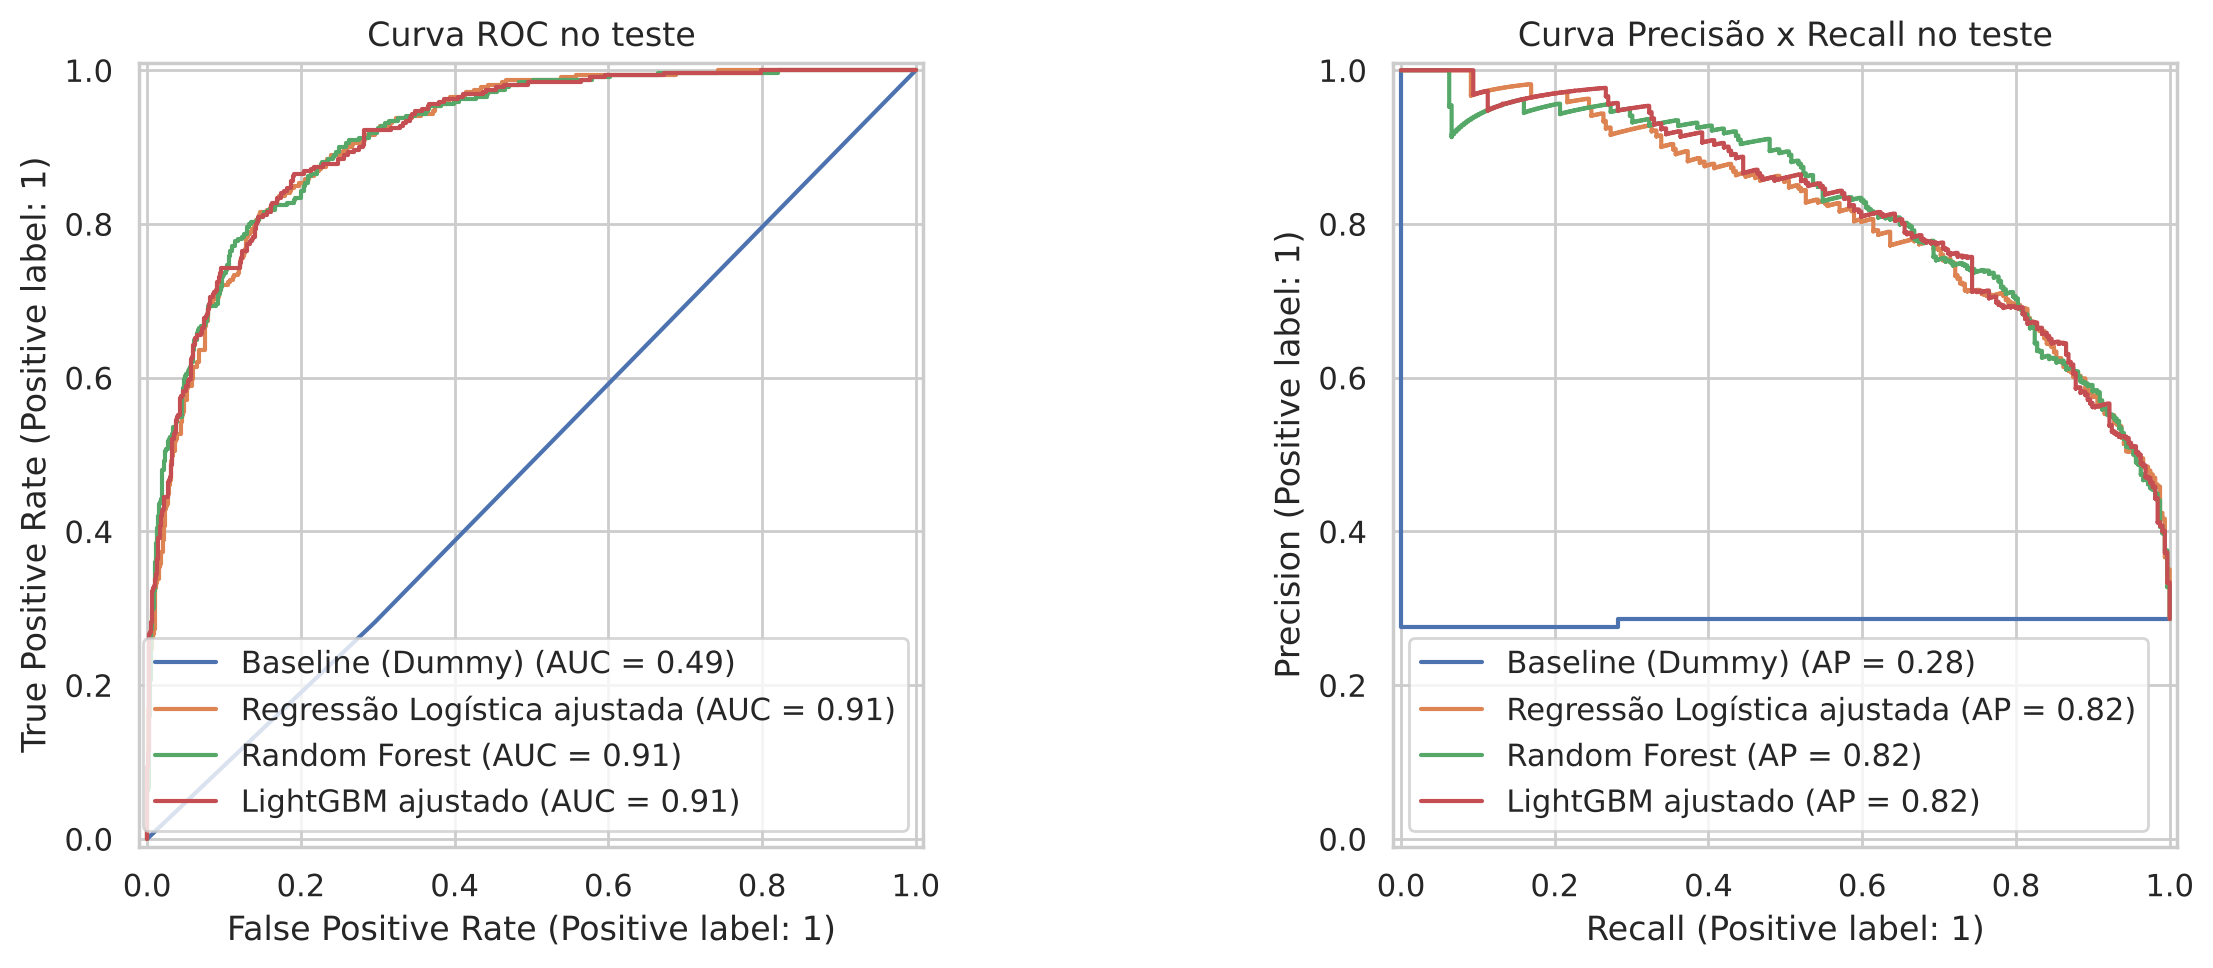

In [15]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 5))
for nome, p in probabilidades.items():
    RocCurveDisplay.from_predictions(y_teste, p, name=nome, ax=eixos[0])
    PrecisionRecallDisplay.from_predictions(y_teste, p, name=nome, ax=eixos[1])
eixos[0].set_title("Curva ROC no teste")
eixos[1].set_title("Curva Precisão x Recall no teste")
plt.tight_layout()
plt.savefig("figuras/05_curvas.png", dpi=150)
plt.show()

In [16]:
cv_ajustados = pd.Series({
    "Regressão Logística ajustada": busca_lr.best_score_,
    "LightGBM ajustado": busca_lgbm.best_score_,
    "Random Forest": comparacao.loc["Random Forest", "ROC-AUC validação"],
}).sort_values(ascending=False)
print("ROC-AUC na validação cruzada (treino):")
print(cv_ajustados.round(4).to_string())

# Regra de escolha definida ANTES de olhar o teste: o melhor na validação cruzada;
# se a diferença para a Regressão Logística for menor que 0,005, fica a Logística (mais simples e interpretável).
melhor = cv_ajustados.index[0]
if cv_ajustados[melhor] - cv_ajustados["Regressão Logística ajustada"] < 0.005:
    melhor = "Regressão Logística ajustada"
modelo_final = finalistas[melhor]
print(f"\nModelo final: {melhor}")

ROC-AUC na validação cruzada (treino):
Regressão Logística ajustada   0.9138
LightGBM ajustado              0.9134
Random Forest                  0.9126

Modelo final: Regressão Logística ajustada


**Modelo final: Regressão Logística (C = 1).** Os três finalistas **empataram**: 0,914, 0,913 e 0,913 na validação cruzada, e 0,913, 0,914 e 0,915 no teste. As diferenças são menores que a variação entre as dobras, de cerca de 0,007. Pela regra definida antes de olhar o teste, fica o modelo mais simples, por três motivos:
1. **Generaliza melhor:** o gap entre treino e validação é de 0,002, contra 0,031 do LightGBM ajustado e 0,082 da Random Forest.
2. **É interpretável:** cada coeficiente vira uma razão de chances que dá para explicar a um gestor de saúde.
3. **É leve e estável** para rodar dentro do app.

Os modelos complexos não acharam nenhum padrão que a Logística não tivesse achado. Isso também é um resultado: a relação entre a rede de saúde e o vazio de urgência é, em boa parte, aditiva.

### 6.1 Ponto de corte

Com pesos balanceados, a probabilidade de 0,5 já não é o corte natural. O corte foi escolhido pelo **maior F1** nas previsões de validação cruzada do **treino** (*out-of-fold*), e nunca no teste. O F1 equilibra duas coisas: não deixar município sem urgência de fora e não marcar à toa quem tem.

Corte escolhido no treino: 0.565
No teste -> recall: 0.815 | precisão: 0.684 | F1: 0.744 | acurácia: 0.839


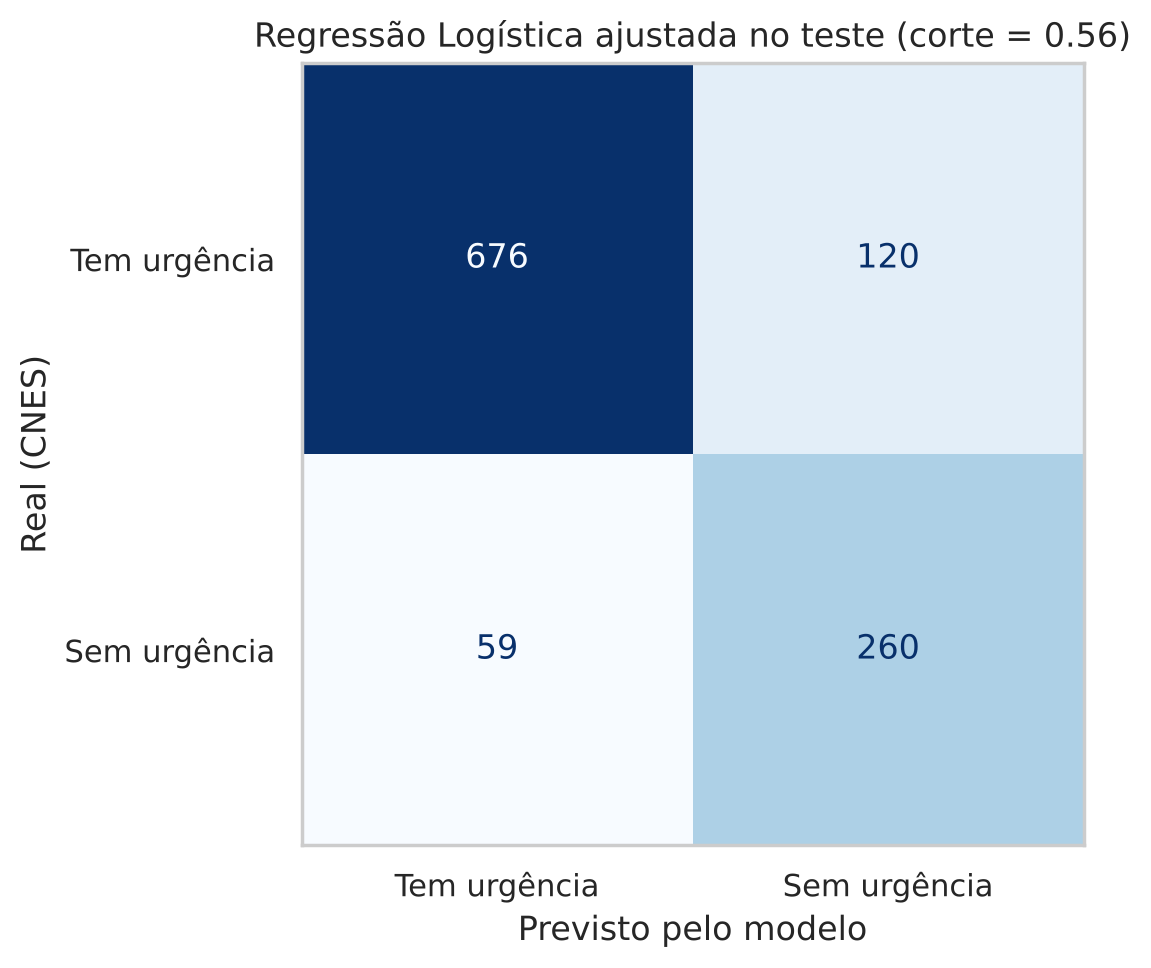

In [17]:
p_oof = cross_val_predict(modelo_final, X_treino, y_treino, cv=validacao, method="predict_proba")[:, 1]
cortes = np.linspace(0.05, 0.95, 181)
f1s = [f1_score(y_treino, (p_oof >= c).astype(int)) for c in cortes]
CORTE = float(cortes[int(np.argmax(f1s))])
p_final = modelo_final.predict_proba(X_teste)[:, 1]
alerta = (p_final >= CORTE).astype(int)
print(f"Corte escolhido no treino: {CORTE:.3f}")
print(f"No teste -> recall: {recall_score(y_teste, alerta):.3f} | precisão: {precision_score(y_teste, alerta):.3f} | "
      f"F1: {f1_score(y_teste, alerta):.3f} | acurácia: {accuracy_score(y_teste, alerta):.3f}")

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_teste, alerta, display_labels=["Tem urgência", "Sem urgência"],
                                        cmap="Blues", values_format="d", ax=ax, colorbar=False)
ax.grid(False)
ax.set_title(f"{melhor} no teste (corte = {CORTE:.2f})")
ax.set_xlabel("Previsto pelo modelo")
ax.set_ylabel("Real (CNES)")
plt.tight_layout()
plt.savefig("figuras/06_matriz_confusao.png", dpi=150)
plt.show()

Com o corte de 0,565, o modelo encontra **8 em cada 10 municípios sem urgência** do teste (recall de 0,815). Quando aponta um município como sem urgência, acerta 68% das vezes (precisão de 0,684). O F1 é 0,744 e a acurácia, 83,9%.

A Estatística chegou a 84,1% de acurácia com 3 variáveis, mas avaliou o modelo nos mesmos dados em que ele foi ajustado. Aqui o número vem de municípios que o modelo nunca viu, e o objetivo é pegar os desassistidos, não maximizar a acurácia.

## 7. Interpretação: importância das variáveis

Três leituras que se completam:
1. os **coeficientes da Regressão Logística**, convertidos em razão de chances por 1 desvio padrão, mostram o **sentido** de cada efeito;
2. a **importância por permutação** no teste mostra quanto a ROC-AUC cai quando os valores de uma variável são embaralhados, para o modelo final;
3. o **ganho do LightGBM** ajustado serve de comparação.

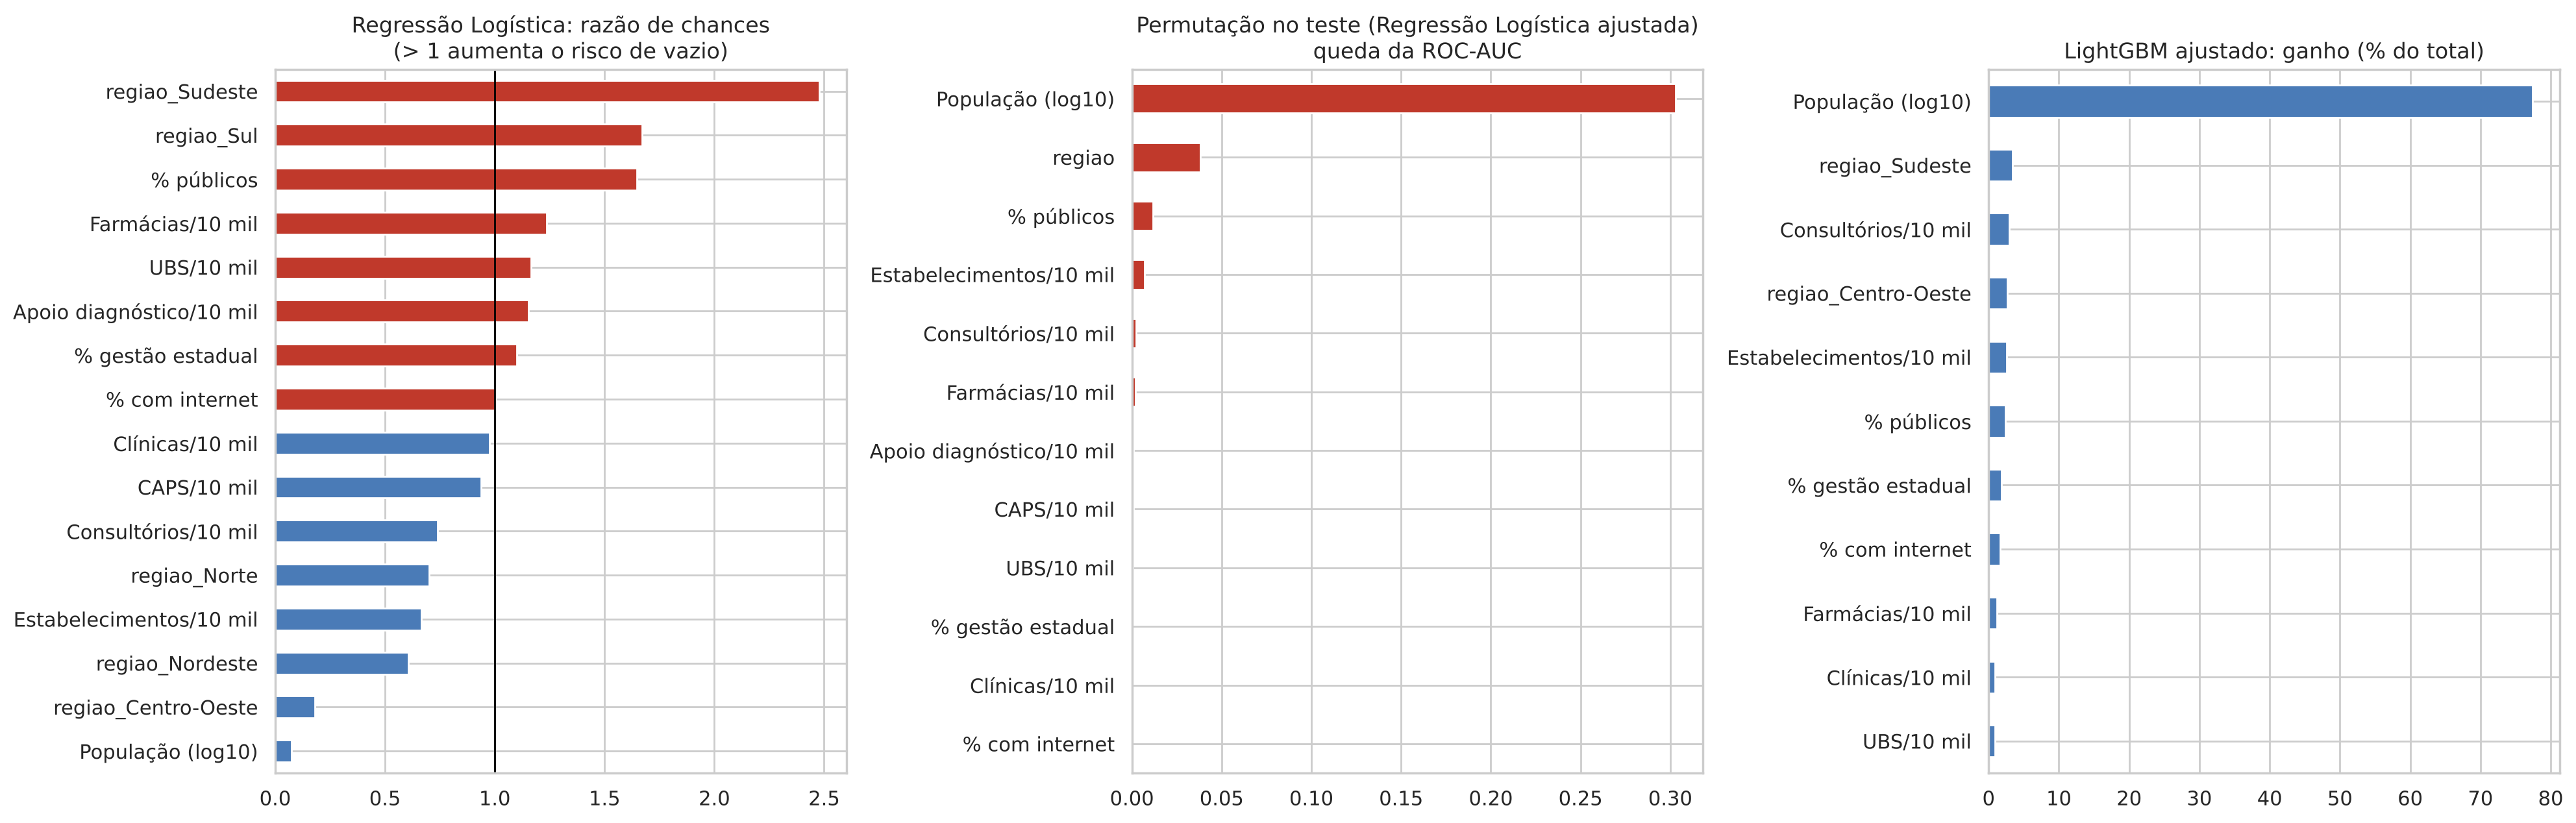

,razão de chances (Logística)
População (log10),0.0729
regiao_Centro-Oeste,0.1797
regiao_Nordeste,0.6063
Estabelecimentos/10 mil,0.6650
regiao_Norte,0.7016
Consultórios/10 mil,0.7389
CAPS/10 mil,0.9371
Clínicas/10 mil,0.9767
% com internet,1.0024
% gestão estadual,1.0986


In [18]:
logistica = busca_lr.best_estimator_
nomes_saida = logistica.named_steps["preparo"].get_feature_names_out()
razao = pd.Series(np.exp(logistica.named_steps["modelo"].coef_[0]), index=nomes_saida)

permutacao = permutation_importance(modelo_final, X_teste, y_teste, scoring="roc_auc",
                                    n_repeats=10, random_state=SEMENTE, n_jobs=-1)
importancia_perm = pd.Series(permutacao.importances_mean, index=ATRIBUTOS).sort_values()

lgbm = busca_lgbm.best_estimator_
ganho = pd.Series(lgbm.named_steps["modelo"].booster_.feature_importance(importance_type="gain"),
                  index=lgbm.named_steps["preparo"].get_feature_names_out())
ganho = (100 * ganho / ganho.sum()).sort_values()

fig, eixos = plt.subplots(1, 3, figsize=(20, 6.5))
r = razao.sort_values()
r.rename(lambda n: NOMES.get(n, n)).plot.barh(ax=eixos[0], color=["#4a7bb7" if v < 1 else "#c0392b" for v in r])
eixos[0].axvline(1, color="black", lw=1)
eixos[0].set_title("Regressão Logística: razão de chances\n(> 1 aumenta o risco de vazio)")
importancia_perm.rename(lambda n: NOMES.get(n, n)).plot.barh(ax=eixos[1], color="#c0392b")
eixos[1].set_title(f"Permutação no teste ({melhor})\nqueda da ROC-AUC")
ganho.tail(11).rename(lambda n: NOMES.get(n, n)).plot.barh(ax=eixos[2], color="#4a7bb7")
eixos[2].set_title("LightGBM ajustado: ganho (% do total)")
plt.tight_layout()
plt.savefig("figuras/07_importancia.png", dpi=150)
plt.show()
pd.DataFrame({"razão de chances (Logística)": razao.rename(lambda n: NOMES.get(n, n))}).sort_values(
    "razão de chances (Logística)")

**Leitura da importância:**
- **O porte da cidade domina.** Embaralhar a população derruba a ROC-AUC em 0,30, e cada 1 desvio padrão a mais em log10(população) divide a chance de vazio por mais de 13 (razão de chances de 0,07).
- **A região vem em segundo** (queda de 0,04): mantido o resto igual, o vazio é mais comum nas cidades pequenas do Sudeste e do Sul e menos comum no Centro-Oeste.
- **O perfil da rede refina** a classificação entre cidades do mesmo tamanho:
    - rede **mais pública** aumenta o risco (razão de chances de 1,65 por desvio padrão), porque nesses lugares o SUS está sozinho;
    - **mais estabelecimentos** e **mais consultórios** por habitante protegem (0,67 e 0,74), porque indicam uma rede diversificada;
    - **mais UBS e farmácias** por habitante aparecem junto com o vazio (1,16 e 1,24): é a atenção básica presente, mas sem retaguarda.
- O LightGBM ajustado aponta as mesmas variáveis no topo, o que dá confiança de que o padrão é real, e não um efeito de um algoritmo só.

Importância indica **associação, não causa**: ter mais UBS não *causa* o vazio de urgência.

## 8. Aplicação: onde o vazio de urgência mais surpreende

O modelo dá a cada município uma pontuação de risco de vazio de urgência, de 0 a 1. Para não avaliar um município com um modelo que já o viu no treino, as pontuações abaixo são **fora da amostra**: cada município recebe a nota de um modelo treinado sem ele (validação cruzada de 5 dobras em toda a base).

Os erros do modelo são a parte mais útil para o gestor:
- **Lacunas inesperadas:** municípios **sem** urgência cujo perfil é de quem **tem**, ou seja, com pontuação baixa. É onde a falta é mais difícil de justificar e onde investir primeiro.
- **Urgência frágil:** municípios **com** urgência cujo perfil é de quem **não tem**, ou seja, com pontuação alta. Costumam depender de uma única unidade, e qualquer fechamento os deixa descobertos.

In [19]:
dados["risco_vazio"] = cross_val_predict(modelo_final, X, y, cv=validacao, method="predict_proba")[:, 1].round(3)
colunas = ["municipio", "uf", "populacao", "ubs", "unidades_urgencia", "risco_vazio", "km_urgencia", "municipio_urgencia"]

lacunas = dados[dados["sem_urgencia"] == 1].nsmallest(10, "risco_vazio")[colunas]
frageis = dados[dados["sem_urgencia"] == 0].nlargest(10, "risco_vazio")[colunas]
print("LACUNAS INESPERADAS: sem urgência, mas com perfil de quem tem")
display(lacunas)
print("URGÊNCIA FRÁGIL: tem urgência, mas com perfil de quem não tem")
display(frageis)

LACUNAS INESPERADAS: sem urgência, mas com perfil de quem tem


,municipio,uf,populacao,ubs,unidades_urgencia,risco_vazio,km_urgencia,municipio_urgencia
5324,Abadia de Goiás,GO,22918,5,0,0.0170,10.5000,Aparecida de Goiânia/GO
150,Uiramutã,RR,16809,3,0,0.0230,99.3000,Normandia/RR
2930,Santana do Paraíso,MG,49978,14,0,0.0350,8.3000,Ipatinga/MG
3228,Paty do Alferes,RJ,31382,14,0,0.0690,4.7000,Miguel Pereira/RJ
1812,Salgado,SE,20874,10,0,0.0700,9.8000,Lagarto/SE
5259,Nova Canaã do Norte,MT,11697,7,0,0.0750,33.1000,Colíder/MT
3971,Campo Magro,PR,32227,8,0,0.0780,12.9000,Campo Largo/PR
257,Santa Bárbara do Pará,PA,22764,6,0,0.0940,6.8000,Benevides/PA
2076,Maraú,BA,25965,11,0,0.0940,19.6000,Itacaré/BA
4154,Ortigueira,PR,24808,12,0,0.0940,31.5000,Telêmaco Borba/PR


URGÊNCIA FRÁGIL: tem urgência, mas com perfil de quem não tem


,municipio,uf,populacao,ubs,unidades_urgencia,risco_vazio,km_urgencia,municipio_urgencia
2518,Estrela Dalva,MG,2176,2,1,0.9890,0.9000,Estrela Dalva/MG
4852,Mariano Moro,RS,1884,2,1,0.9880,0.1000,Mariano Moro/RS
2285,Arapuá,MG,2662,1,1,0.9830,0.1000,Arapuá/MG
3864,Taquaral,SP,2645,1,1,0.9820,0.0000,Taquaral/SP
4247,Santo Antônio do Paraíso,PR,2070,1,1,0.9800,0.4000,Santo Antônio do Paraíso/PR
2798,Passabém,MG,1601,1,1,0.9780,0.0000,Passabém/MG
4792,Guabiju,RS,1441,1,1,0.9780,0.1000,Guabiju/RS
5099,Vista Gaúcha,RS,2843,2,1,0.9730,0.2000,Vista Gaúcha/RS
3746,Ribeira,SP,3151,2,1,0.9720,0.0000,Ribeira/SP
3084,Veríssimo,MG,3476,2,1,0.9690,0.1000,Veríssimo/MG


**Leitura:**
- Entre as **lacunas inesperadas** aparecem cidades médias, como **Santana do Paraíso (MG)**, com quase 50 mil habitantes, e **Campo Magro (PR)**, com 32 mil. As duas dependem da urgência da cidade vizinha. Também aparece **Uiramutã (RR)**, a 99 km em linha reta da urgência mais próxima.
- A **urgência frágil** está em cidades de 1,5 a 3,5 mil habitantes que têm **uma única** unidade de urgência.

São os dois grupos em que o PulsoVision e o gestor público devem chegar primeiro.

In [20]:
pacote = {"modelo": modelo_final, "nome": melhor, "atributos": ATRIBUTOS, "corte": CORTE, "versao": "1.0",
          "fonte": "CNES/DataSUS set/2026 + IBGE 2026"}
joblib.dump(pacote, "modelo_vazio_urgencia.joblib")
print(f"Modelo salvo em modelo_vazio_urgencia.joblib ({melhor}, corte {CORTE:.2f})")

Modelo salvo em modelo_vazio_urgencia.joblib (Regressão Logística ajustada, corte 0.56)


## 9. PulsoVision ponta a ponta: do sintoma à unidade certa

Aqui o modelo deixa de ser uma análise isolada e entra no app. A função `pulso()` faz o caminho que o PulsoVision vai fazer com o cidadão:

1. **Recebe** as respostas do cidadão: idade, sintomas, há quantos dias começou, se tem doença crônica, cidade e localização.
2. **Triagem por regras**, inspirada no protocolo de Manchester:
    - dor no peito, falta de ar, desmaio, sangramento, confusão ou convulsão levam ao **VERMELHO**;
    - febre há 3 dias ou mais, vômitos, dor forte, ou qualquer sintoma em quem é do grupo de risco (60 anos ou mais, gestante, doença crônica), levam ao **AMARELO**;
    - o resto fica **VERDE**.

    A IA não diagnostica e nunca baixa a cor.
3. **Modelo de ML** (esta disciplina): dá o **risco de vazio de urgência** da cidade do cidadão. Quando a cidade não tem urgência, ou tem risco alto, o PulsoVision já indica a **urgência de referência** (a mais próxima, calculada com as coordenadas do CNES), para a pessoa saber para onde ir antes de piorar.
4. **Foto** (disciplina 07, Redes Neurais): quando a CNN sinaliza a foto como suspeita, a cor sobe para amarelo. Aqui a foto é só a entrada opcional `sinal_foto`; a CNN entra no produto final.
5. **Lotação medida pelo totem** (disciplinas 01 a 04): em Guarulhos, onde está o nosso totem, a UBS é escolhida pelo **menor tempo estimado** (caminhada + fila), com o mesmo ranking que a API de Python devolve em `/indicadores`. UBS lotadas ficam de fora.

**De onde vem a lotação:**
- Com a API de Python rodando, com o totem do Wokwi enviando leituras, preencha `URL_API = "http://localhost:5000"`. O notebook lê o `/indicadores` **ao vivo**.
- Sem a API, como no Google Colab, usa um retrato. Na **UBS Jardim Paulista**, é uma leitura **real** do nosso totem no Wokwi: 6 pessoas, LOTADO. Nas UBS vizinhas, os totens são **simulados** com o mesmo contrato JSON v1.0 e as mesmas regras da API. A instalação de totens nelas fica como evolução futura.

As unidades e as coordenadas são **reais**, do CNES/DataSUS.

In [21]:
# Unidades reais do CNES/DataSUS (set/2026) em Guarulhos/SP, as mais próximas da UBS Jardim Paulista,
# onde está o totem do PulsoVision. Só dados públicos do estabelecimento: código, nome e coordenadas.
UNIDADES = pd.DataFrame([
    ("4048296", "UBS Jardim Paulista", "UBS", -23.436977, -46.548290),
    ("3179613", "UBS Continental", "UBS", -23.432725, -46.549773),
    ("2035995", "UBS Jardim Rosa de França", "UBS", -23.443754, -46.556505),
    ("2049961", "UBS Vila Rio de Janeiro", "UBS", -23.440666, -46.536500),
    ("2062097", "UBS Jardim Palmira", "UBS", -23.435496, -46.561646),
    ("2036002", "UBS Jardim Flor da Montanha", "UBS", -23.447335, -46.539841),
    ("9242295", "UPA Paulista", "UPA", -23.436759, -46.548759),
    ("5595746", "Pronto Atendimento Paraventi", "UPA", -23.449922, -46.526694),
], columns=["cnes", "nome_unidade", "tipo_unidade", "lat", "lon"])

# Mesmas regras do totem (Regras.h) e da API de Python (services/leituras.py)
AREA_FILA_CM, ESPACO_POR_PESSOA_CM = 400.0, 60.0
LIMIAR_FILA_LONGA_CM, LIMIAR_FILA_MEDIA_CM = 120.0, 250.0


def leitura_totem(cnes, distancia_cm, movimento):
    """Monta uma leitura no contrato JSON v1.0, decidindo o status como o totem e a API decidem."""
    unidade = UNIDADES.set_index("cnes").loc[cnes]
    fila = "LONGA" if distancia_cm <= LIMIAR_FILA_LONGA_CM else "MEDIA" if distancia_cm <= LIMIAR_FILA_MEDIA_CM else "CURTA"
    fluxo = "FLUXO" if movimento else "SEM_FLUXO"
    if fila == "LONGA":
        status, motivo = "LOTADO", "FILA_LONGA"
    elif fila == "MEDIA":
        status, motivo = ("ALERTA", "FILA_MEDIA") if movimento else ("LOTADO", "FILA_PARADA")
    else:
        status, motivo = "OK", "FILA_CURTA"
    pessoas = max(0, int((AREA_FILA_CM - distancia_cm) / ESPACO_POR_PESSOA_CM + 0.5))
    return {"versao_contrato": "1.0", "id_totem": f"TOTEM-{cnes}-01", "cnes": cnes,
            "nome_unidade": unidade["nome_unidade"], "tipo_unidade": unidade["tipo_unidade"],
            "cod_municipio": "351880", "fila_distancia_cm": distancia_cm, "fila_status": fila,
            "movimento": movimento, "movimento_status": fluxo, "pessoas_aguardando": pessoas,
            "status": status, "motivo": motivo}


# Retrato de lotação usado quando a API não está no ar (por exemplo, no Google Colab):
# - UBS Jardim Paulista: leitura REAL do nosso totem no Wokwi (id_leitura 7: fila a 42,5 cm, 6 pessoas, LOTADO);
# - UBS vizinhas: totens SIMULADOS com o mesmo contrato e as mesmas regras (evolução: instalar totens nelas).
RETRATO_TOTENS = [
    leitura_totem("4048296", 42.5, True),
    leitura_totem("3179613", 330.0, True),
    leitura_totem("2035995", 180.0, True),
    leitura_totem("2049961", 380.0, True),
    leitura_totem("2062097", 95.0, True),
    leitura_totem("2036002", 300.0, False),
]

URL_API = ""   # com a API de Python rodando no mesmo computador: "http://localhost:5000"


def consultar_lotacao():
    """Lê o ranking de lotação: ao vivo pela API (/indicadores) ou pelo retrato dos totens."""
    if URL_API:
        try:
            with urllib.request.urlopen(f"{URL_API}/indicadores", timeout=3) as resposta:
                ranking = json.load(resposta)["ranking_unidades"]
            print(f"Lotação ao vivo: {URL_API}/indicadores ({len(ranking)} unidade(s) com totem)")
            return pd.DataFrame([{"cnes": u["cnes"], "situacao": u["situacao_atual"],
                                  "pessoas_agora": u["pessoas_agora"], "origem": "API ao vivo"} for u in ranking])
        except OSError as erro:
            print(f"API fora do ar ({erro}); usando o retrato dos totens.")
    origem = {"4048296": "totem real (Wokwi)"}
    return pd.DataFrame([{"cnes": l["cnes"], "situacao": l["status"], "pessoas_agora": l["pessoas_aguardando"],
                          "origem": origem.get(l["cnes"], "totem simulado")} for l in RETRATO_TOTENS])


lotacao = consultar_lotacao()
UNIDADES.merge(lotacao, on="cnes", how="left").fillna({"situacao": "—", "origem": "sem totem (UPA 24 h)"})

,cnes,nome_unidade,tipo_unidade,lat,lon,situacao,pessoas_agora,origem
0,4048296,UBS Jardim Paulista,UBS,-23.4370,-46.5483,LOTADO,6.0000,totem real (Wokwi)
1,3179613,UBS Continental,UBS,-23.4327,-46.5498,OK,1.0000,totem simulado
2,2035995,UBS Jardim Rosa de França,UBS,-23.4438,-46.5565,ALERTA,4.0000,totem simulado
3,2049961,UBS Vila Rio de Janeiro,UBS,-23.4407,-46.5365,OK,0.0000,totem simulado
4,2062097,UBS Jardim Palmira,UBS,-23.4355,-46.5616,LOTADO,5.0000,totem simulado
5,2036002,UBS Jardim Flor da Montanha,UBS,-23.4473,-46.5398,OK,2.0000,totem simulado
6,9242295,UPA Paulista,UPA,-23.4368,-46.5488,—,NaN,sem totem (UPA 24 h)
7,5595746,Pronto Atendimento Paraventi,UPA,-23.4499,-46.5267,—,NaN,sem totem (UPA 24 h)


In [22]:
VERMELHO = {"dor_no_peito": "dor no peito", "falta_de_ar": "falta de ar", "desmaio": "desmaio",
            "sangramento": "sangramento", "confusao": "confusão mental", "convulsao": "convulsão"}
AMARELO = {"vomitos": "vômitos", "dor_forte": "dor forte"}
SINTOMAS_LEVES = ["febre", "dor_no_corpo", "dor_de_cabeca", "tosse", "diarreia"]
MINUTOS_POR_KM, MINUTOS_POR_PESSOA = 15, 10   # caminhada e espera estimada por pessoa na fila


def km(valor):
    return f"{valor:.1f} km".replace(".", ",")


def distancia_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))


def triagem(c: dict) -> tuple[str, str]:
    """Regras inspiradas no protocolo de Manchester. A IA não diagnostica e nunca baixa a cor."""
    graves = [texto for chave, texto in VERMELHO.items() if c.get(chave)]
    if graves:
        return "VERMELHO", "sinal de alarme: " + ", ".join(graves)
    grupo_risco = c.get("idade", 0) >= 60 or c.get("gestante") or c.get("doenca_cronica")
    moderados = [texto for chave, texto in AMARELO.items() if c.get(chave)]
    if c.get("febre") and c.get("dias", 0) >= 3:
        moderados.append(f"febre há {c['dias']} dias")
    if c.get("sinal_foto") == "suspeito":
        moderados.append("foto sinalizada pela CNN")
    if grupo_risco and any(c.get(s) for s in SINTOMAS_LEVES + list(AMARELO)):
        moderados.append("grupo de risco com sintomas")
    if moderados:
        return "AMARELO", ", ".join(moderados)
    return "VERDE", "sintomas leves, sem sinal de alarme"


def risco_da_cidade(municipio: str, uf: str) -> pd.Series:
    """Linha do município na base, com a pontuação do modelo de ML."""
    linha = base[(dados["municipio"] == municipio) & (dados["uf"] == uf)]
    info = dados.loc[linha.index[0]].copy()
    info["risco_modelo"] = float(modelo_final.predict_proba(linha[ATRIBUTOS])[:, 1][0])
    return info


def melhor_ubs(lat, lon):
    opcoes = UNIDADES[UNIDADES["tipo_unidade"] == "UBS"].merge(lotacao, on="cnes", how="left")
    opcoes["km"] = distancia_km(lat, lon, opcoes["lat"], opcoes["lon"])
    opcoes["minutos"] = opcoes["km"] * MINUTOS_POR_KM + opcoes["pessoas_agora"].fillna(0) * MINUTOS_POR_PESSOA
    livres = opcoes[opcoes["situacao"] != "LOTADO"]
    return (livres if len(livres) else opcoes).sort_values("minutos").iloc[0], opcoes


def pulso(c: dict) -> dict:
    cor, motivo = triagem(c)
    cidade = risco_da_cidade(c["municipio"], c["uf"])
    tem_totem = c["municipio"] == "Guarulhos"
    sem_urgencia = bool(cidade["sem_urgencia"])
    referencia = (f"{cidade['urgencia_mais_proxima']}, em {cidade['municipio_urgencia']} "
                  f"({km(cidade['km_urgencia'])})")
    vazio = sem_urgencia or cidade["risco_modelo"] >= CORTE

    if cor == "VERMELHO":
        if tem_totem:
            upas = UNIDADES[UNIDADES["tipo_unidade"] == "UPA"].copy()
            upas["km"] = distancia_km(c["lat"], c["lon"], upas["lat"], upas["lon"])
            destino = upas.sort_values("km").iloc[0]
            onde = f"{destino['nome_unidade']} ({km(destino['km'])}), que funciona 24 h"
        else:
            onde = referencia + (": sua cidade não tem pronto atendimento" if sem_urgencia else "")
        mensagem = f"VERMELHO: vá AGORA à urgência mais perto: {onde}. Se não conseguir ir, ligue 192."
    elif tem_totem:
        destino, opcoes = melhor_ubs(c["lat"], c["lon"])
        pessoas = int(destino["pessoas_agora"])
        lotadas = opcoes[opcoes["situacao"] == "LOTADO"]["nome_unidade"].tolist()
        aviso = (f" Evite agora: {' e '.join(lotadas)} ({'lotadas' if len(lotadas) > 1 else 'lotada'})."
                 if lotadas else "")
        if cor == "AMARELO":
            mensagem = (f"AMARELO: procure HOJE a {destino['nome_unidade']} ({km(destino['km'])}), "
                        f"fila agora: {pessoas} pessoa{'s' if pessoas != 1 else ''}.{aviso}")
        else:
            mensagem = (f"VERDE: cuide-se em casa, com repouso e muita água. Se precisar, a menor espera agora "
                        f"é na {destino['nome_unidade']} ({km(destino['km'])}).")
    else:
        plano = f" Sua cidade não tem pronto atendimento: se piorar, a referência é {referencia}." if vazio else ""
        if cor == "AMARELO":
            mensagem = f"AMARELO: procure HOJE a UBS de {c['municipio']}.{plano}"
        else:
            mensagem = f"VERDE: cuide-se em casa, com repouso e muita água.{plano}"
    return {"cor": cor, "motivo": motivo, "cidade": f"{c['municipio']}/{c['uf']}",
            "risco de vazio da cidade (ML)": round(cidade["risco_modelo"], 2), "mensagem": mensagem}


CIDADAOS = {
    "Dona Cleide, 72 anos, Guarulhos/SP": dict(
        municipio="Guarulhos", uf="SP", lat=-23.4380, lon=-46.5500, idade=72, febre=True, dias=4,
        vomitos=True, doenca_cronica=True),
    "Seu João, 50 anos, Guarulhos/SP": dict(
        municipio="Guarulhos", uf="SP", lat=-23.4460, lon=-46.5300, idade=50, falta_de_ar=True),
    "Ana, 30 anos, Guarulhos/SP": dict(
        municipio="Guarulhos", uf="SP", lat=-23.4405, lon=-46.5440, idade=30, febre=True, dias=1,
        dor_no_corpo=True),
    "Dona Rosa, 68 anos, Cananéia/SP": dict(
        municipio="Cananéia", uf="SP", lat=-25.0120, lon=-47.9302, idade=68, dor_no_peito=True),
    "Pedro, 34 anos, Cananéia/SP": dict(
        municipio="Cananéia", uf="SP", lat=-25.0120, lon=-47.9302, idade=34, febre=True, dias=3,
        dor_no_corpo=True),
}
respostas = {nome: pulso(c) for nome, c in CIDADAOS.items()}
for nome, r in respostas.items():
    print(f"{nome}  [risco de vazio da cidade: {r['risco de vazio da cidade (ML)']:.2f}]\n"
          f"  [{r['cor']}] {r['motivo']}\n  -> {r['mensagem']}\n")

Dona Cleide, 72 anos, Guarulhos/SP  [risco de vazio da cidade: 0.00]
  [AMARELO] vômitos, febre há 4 dias, grupo de risco com sintomas
  -> AMARELO: procure HOJE a UBS Continental (0,6 km), fila agora: 1 pessoa. Evite agora: UBS Jardim Paulista e UBS Jardim Palmira (lotadas).

Seu João, 50 anos, Guarulhos/SP  [risco de vazio da cidade: 0.00]
  [VERMELHO] sinal de alarme: falta de ar
  -> VERMELHO: vá AGORA à urgência mais perto: Pronto Atendimento Paraventi (0,6 km), que funciona 24 h. Se não conseguir ir, ligue 192.

Ana, 30 anos, Guarulhos/SP  [risco de vazio da cidade: 0.00]
  [VERDE] sintomas leves, sem sinal de alarme
  -> VERDE: cuide-se em casa, com repouso e muita água. Se precisar, a menor espera agora é na UBS Vila Rio de Janeiro (0,8 km).

Dona Rosa, 68 anos, Cananéia/SP  [risco de vazio da cidade: 0.33]
  [VERMELHO] sinal de alarme: dor no peito
  -> VERMELHO: vá AGORA à urgência mais perto: Pronto Atendimento Mun Armando Jose Prado Barone I Comprida, em Ilha Comprida/SP (2

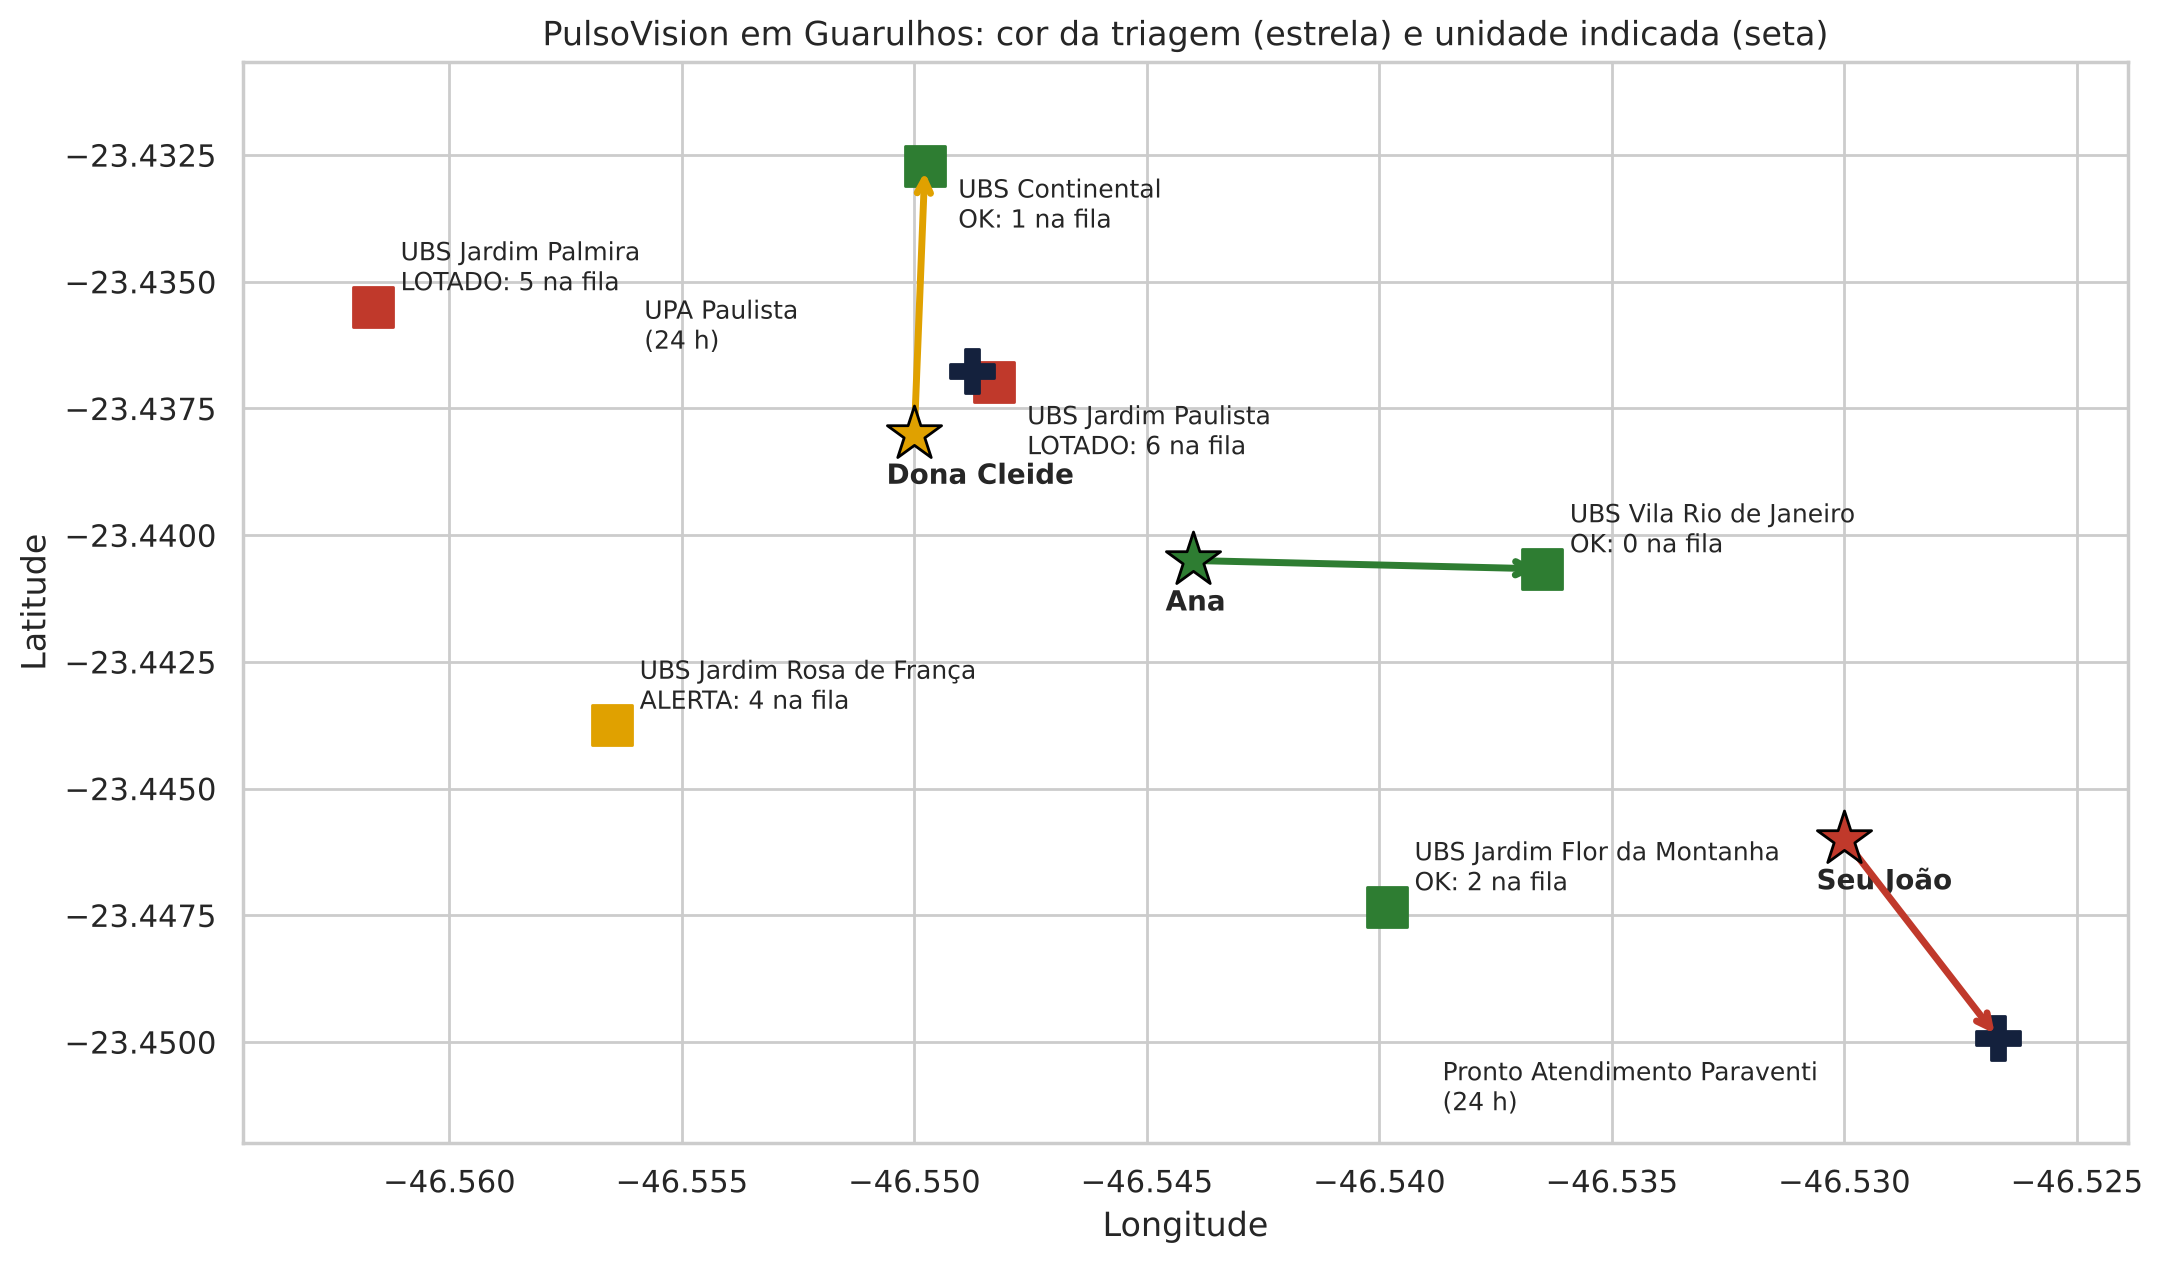

In [23]:
cores_status = {"OK": "#2e7d32", "ALERTA": "#e0a100", "LOTADO": "#c0392b"}
cores_triagem = {"VERDE": "#2e7d32", "AMARELO": "#e0a100", "VERMELHO": "#c0392b"}
mapa = UNIDADES.merge(lotacao, on="cnes", how="left")
deslocamento = {"UPA Paulista": (-118, 8), "UBS Jardim Paulista": (12, -26), "UBS Continental": (12, -22),
                "Pronto Atendimento Paraventi": (-200, -26)}

fig, ax = plt.subplots(figsize=(11, 8))
for _, u in mapa.iterrows():
    if u["tipo_unidade"] == "UPA":
        ax.scatter(u["lon"], u["lat"], marker="P", s=260, color="#14213d", zorder=3)
        rotulo = f"{u['nome_unidade']}\n(24 h)"
    else:
        ax.scatter(u["lon"], u["lat"], marker="s", s=200, color=cores_status.get(u["situacao"], "gray"), zorder=3)
        rotulo = f"{u['nome_unidade']}\n{u['situacao']}: {int(u['pessoas_agora'])} na fila"
    ax.annotate(rotulo, (u["lon"], u["lat"]), textcoords="offset points",
                xytext=deslocamento.get(u["nome_unidade"], (10, 6)), fontsize=9)

for nome, c in CIDADAOS.items():
    if c["municipio"] != "Guarulhos":
        continue
    cor = respostas[nome]["cor"]
    if cor == "VERMELHO":
        upas = UNIDADES[UNIDADES["tipo_unidade"] == "UPA"].copy()
        upas["km"] = distancia_km(c["lat"], c["lon"], upas["lat"], upas["lon"])
        destino = upas.sort_values("km").iloc[0]
    else:
        destino, _ = melhor_ubs(c["lat"], c["lon"])
    ax.scatter(c["lon"], c["lat"], marker="*", s=420, color=cores_triagem[cor], edgecolor="black", zorder=4)
    ax.annotate(nome.split(",")[0], (c["lon"], c["lat"]), textcoords="offset points", xytext=(-10, -18),
                fontsize=10, fontweight="bold")
    ax.annotate("", xy=(destino["lon"], destino["lat"]), xytext=(c["lon"], c["lat"]),
                arrowprops=dict(arrowstyle="->", color=cores_triagem[cor], lw=2.5))

ax.margins(x=0.08, y=0.12)
ax.set_title("PulsoVision em Guarulhos: cor da triagem (estrela) e unidade indicada (seta)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect(1 / np.cos(np.radians(-23.44)))
plt.tight_layout()
plt.savefig("figuras/08_mapa_encaminhamento.png", dpi=150)
plt.show()

**Leitura:**
- **Dona Cleide** (Guarulhos) é do grupo de risco e tem febre há 4 dias com vômitos: **amarelo**. A UBS Jardim Paulista, a mais perto, está **lotada segundo o totem**, então o PulsoVision a manda para a UBS Continental, com 1 pessoa na fila.
- **Seu João** (Guarulhos) está com falta de ar: **vermelho**, e vai para a urgência 24 h mais perto.
- **Ana** (Guarulhos) tem sintomas leves: **verde**, com cuidado em casa e a UBS de menor espera, caso precise.
- **Dona Rosa** (Cananéia/SP) sente dor no peito. Cananéia **não tem pronto atendimento**, e o app manda direto para a urgência de referência, em Ilha Comprida, a 29,9 km, com o 192 como alternativa.
- **Pedro** (Cananéia/SP) recebe **amarelo**: deve ir hoje à UBS da cidade, mas já sabe para onde ir se piorar.

A pontuação do modelo para Cananéia é de 0,33, abaixo do corte, mesmo sem urgência no CNES: é uma das "lacunas inesperadas". Por isso o app **usa o cadastro real** para encaminhar o cidadão e usa o **modelo** para explicar e priorizar o território.

É a coluna vertebral do projeto rodando num lugar só:
- o **sensor** (AICSS) mede a fila;
- a **API** (Python) organiza as leituras;
- os **medalhões** (Databricks e AWS) guardam o histórico;
- a **Estatística** e este **modelo de ML** mostram onde falta urgência;
- a **CNN** (Redes Neurais) entra pela foto;
- e o cidadão recebe **uma frase só**, por voz, dizendo o que fazer e para onde ir.

## 10. Benefícios, limitações e evolução

**Benefícios para o público:**
- Quem mora numa das 1.595 cidades sem urgência fica sabendo **antes de precisar** para onde ir numa emergência, e a que distância.
- Em Guarulhos, onde o totem mede a fila, o cidadão evita a UBS lotada e vai à de menor espera.
- O gestor recebe duas listas de prioridade: as **lacunas inesperadas** e as cidades de **urgência frágil**.

**Limitações, declaradas com honestidade:**
- **O alvo vem do cadastro (CNES).** Um hospital cadastrado nem sempre tem pronto-socorro aberto, e o cadastro pode estar desatualizado. O modelo aprende o retrato do cadastro de setembro de 2026.
- **Associação, não causa.** Ter mais UBS por habitante não *causa* a falta de urgência: as duas coisas são marcas do mesmo perfil, o de cidade pequena e muito pública.
- **Distância em linha reta.** Os km até a urgência de referência ignoram estradas, rios e balsas. No interior do Norte, o tempo real pode ser muito maior.
- **Totens simulados.** Só a UBS Jardim Paulista tem leitura real do nosso totem. As vizinhas usam o mesmo contrato e as mesmas regras, mas com valores simulados.
- **Triagem por regras simplificadas.** As regras são inspiradas no protocolo de Manchester, mas **não o substituem**, e o PulsoVision nunca diagnostica.

**Evoluções futuras:**
- usar tempo de deslocamento real, por estradas, no lugar da linha reta;
- acrescentar leitos, equipes e horários de funcionamento do CNES;
- instalar totens nas UBS vizinhas;
- re-treinar o modelo a cada nova competência do CNES.